# Fase 3 — Clasificación del desenlace de víctimas de tránsito (Paraguay, 2021)
**Integrantes:** Alan Alcaraz, Leandro Ferreira y Jorge Rios.

**Pregunta original:** ¿En qué medida motocicleta, sexo, edad y territorio se asocian con fallecer en un siniestro vial? Respondemos parcialmente: no tenemos una tabla que vincule las cuatro dimensiones por víctima. El experimento principal clasifica **herido (0) / fallecido (1)** usando solamente **sexo y grupo de edad** de 12.2.1; H1–H4 aportan evidencia complementaria en sus fuentes respectivas.

**Cómo estudiar este notebook:** datos → preparación → modelos → validación cruzada → evaluación → errores → interpretación y límites → H1–H4 → conclusiones. El anexo conserva grillas y tablas detalladas. Las funciones extensas siguen en `src/`; cada método y resultado científico se explica aquí. CRISP-DM conecta preparación, modelado, evaluación y comunicación.

**Límite fundamental:** 5.493 filas reconstruyen frecuencias oficiales, no historias individuales originales. Solo hay 16 perfiles sexo × edad. No se unen artificialmente fuentes, no se demuestra independencia por siniestro ni causalidad y no se recomienda uso clínico o individual.

## 1. Datos y preparación reproducible
La tabla 12.2.1 relaciona sexo, edad y desenlace mediante **conteos**. Repetir una fila según su conteo facilita reproducir el experimento anterior, pero no agrega información. El identificador solo enumera la expansión; nunca se usa para predecir.

`reconstruir()` verifica frecuencias y conserva las edades desconocidas. `regenerar_resumenes()` coteja los resúmenes de territorio, meses y rutas con sus originales. Ambas funciones están en `src/preparar_datos.py`. Las Fases 1 y 2 históricas se conservan y no se ejecutan para reconstruir esta fase.

Ejecutar todas las celdas desde un kernel reiniciado, usando el entorno de `requirements-lock.txt`. La semilla 42 fija las decisiones aleatorias; no vuelve independientes las frecuencias.

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: División, Preprocesamiento y Modelos
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Métricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score,
    confusion_matrix, brier_score_loss
)

# Fijación de semilla para reproducibilidad matemática
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configuración de estilo gráfico
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "figure.dpi": 100,
    "font.size": 10.5,
    "axes.labelsize": 11.5,
    "axes.titlesize": 12.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
    "figure.titlesize": 13.5
})

def resolver_rutas():
    cwd = os.path.abspath(os.getcwd())
    candidatos_base = [cwd, os.path.abspath(os.path.join(cwd, "..")), os.path.abspath(os.path.join(cwd, "../.."))]
    ruta_base = next((c for c in candidatos_base if os.path.isdir(os.path.join(c, "output")) and os.path.isdir(os.path.join(c, "data"))), cwd)
    
    ruta_data = os.path.join(ruta_base, "data")
    ruta_output = os.path.join(ruta_base, "output")
    ruta_src = os.path.join(ruta_base, "src")
    
    os.makedirs(ruta_output, exist_ok=True)
    return ruta_base, ruta_data, ruta_output, ruta_src

BASE_DIR, DATA_DIR, OUTPUT_DIR, SRC_DIR = resolver_rutas()
print(f"[OK] Entorno configurado con semilla {RANDOM_STATE}")
print(f"     Directorio Base:   {BASE_DIR}")
print(f"     Directorio Output: {OUTPUT_DIR}")
from pathlib import Path
from sklearn.preprocessing import OrdinalEncoder, FunctionTransformer
from functools import partial
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import balanced_accuracy_score, make_scorer, average_precision_score
from IPython.display import display, Markdown
sys.path.insert(0, BASE_DIR)
from src.preparar_datos import reconstruir, regenerar_resumenes
from src.complementos_fase3 import (calcular_diagnosticos, mostrar_complementos,
                                    publicar_resultados, preparar_contexto)
from src.auditoria_fase3 import complementos_auditados
_, auditoria_fuente = reconstruir(Path(BASE_DIR))
regenerar_resumenes(Path(BASE_DIR))

from IPython import get_ipython
if get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('retina')

[OK] Entorno configurado con semilla 42
     Directorio Base:   C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience
     Directorio Output: C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\output


In [2]:
df_demografico = pd.read_csv(Path(OUTPUT_DIR) / 'victimas_individual_limpio.csv')
assert len(df_demografico) == 5493
assert set(df_demografico.es_fallecido.unique()) == {0, 1}
assert df_demografico[['sexo', 'grupo_edad', 'es_fallecido']].notna().all().all()
assert df_demografico.es_fallecido.eq(df_demografico.gravedad.eq('Fallecido').astype(int)).all()
cantidad_perfiles = len(df_demografico[['sexo', 'grupo_edad']].drop_duplicates())
assert cantidad_perfiles == 16
print(f'{len(df_demografico):,} frecuencias; {int(df_demografico.es_fallecido.sum())} fallecidos; '
      f'{cantidad_perfiles} perfiles; prevalencia {df_demografico.es_fallecido.mean():.2%}.')
display(df_demografico.groupby('gravedad').size().rename('víctimas').to_frame())

5,493 frecuencias; 980 fallecidos; 16 perfiles; prevalencia 17.84%.


,víctimas
gravedad,
Fallecido,980
Herido,4513


### 1.1. Variables, desconocidos y partición
Elegimos `sexo` y `grupo_edad` porque están observados conjuntamente con gravedad en 12.2.1. Excluimos `gravedad` (revela el objetivo), identificador y columnas que repiten sexo/edad.

Hay **4.832 menores de 60 conocidos, 308 de 60 o más y 353 con edad ignorada**. `Ignorado` permanece como categoría del modelo; `edad_orden` y `es_adulto_mayor` son ausentes en esos 353 registros. Solo los contrastes etarios excluyen desconocidos.

Se reserva 20 % con semilla 42 y estratificación para mantener aproximadamente la proporción de fallecidos. El orden del CSV es una expansión por categorías, no una fecha: imponerle un corte temporal sería incorrecto.

**Pipeline:** OneHotEncoder convierte categorías en indicadores 0/1, elimina una referencia por variable y aprende categorías dentro de cada pliegue. Las referencias son Hombre y 0–13 años; con el dominio observado hay ocho indicadores. `handle_unknown='ignore'` permite transformar categorías ausentes del entrenamiento, pero no aprender su señal: con `drop='first'` quedan como la referencia. No hace falta escalar estos indicadores para los modelos utilizados.

In [3]:
# 1. Selección de variables parsimoniosas (sin redundancia colineal)
X_demog = df_demografico[['sexo', 'grupo_edad']].copy()
y_demog = df_demografico['es_fallecido'].astype(int).values

# 2. Partición Estratificada 80/20
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_demog, y_demog,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_demog
)

# 3. Pipeline de preprocesamiento unificado
columnas_categoricas = ['sexo', 'grupo_edad']
preprocesador = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), columnas_categoricas)
    ],
    remainder='drop'
)

print(f"Distribución del target en Train (N = {len(y_train_d)}): {np.bincount(y_train_d)[1]} fallecidos ({np.mean(y_train_d)*100:.2f}%)")
print(f"Distribución del target en Test  (N = {len(y_test_d)}): {np.bincount(y_test_d)[1]} fallecidos ({np.mean(y_test_d)*100:.2f}%)")
assert not set(X_train_d.index) & set(X_test_d.index)
assert list(X_train_d.columns) == ['sexo', 'grupo_edad']

Distribución del target en Train (N = 4394): 784 fallecidos (17.84%)
Distribución del target en Test  (N = 1099): 196 fallecidos (17.83%)


## 2. Modelos y línea base
**Dummy** predice siempre herido: establece qué logra una regla trivial ante el desbalance (17,84 % fallecidos). Los candidatos son:

| Familia | Modelo | Idea y control de complejidad |
|---|---|---|
| Lineal | Regresión logística | Combina indicadores; `C` controla la regularización |
| Árboles | Árbol de decisión | Aprende reglas e interacciones; profundidad y tamaño mínimo de hoja limitan complejidad |
| Árboles | Random Forest | Combina árboles; no constituye una familia diferente del árbol |
| Probabilística generativa | Naive Bayes categórico | Usa frecuencias por categoría y supone independencia de sexo/edad dado el desenlace |

Se mantienen `class_weight='balanced'` para los tres originales y prior 0,5/0,5 para Bayes. Esto da prioridad a fallecidos sin inventar filas, pero **sus puntajes no son probabilidades individuales calibradas**. No se aplica SMOTE ni se elige umbral con test.

Bayes usa OrdinalEncoder como **índice nominal**, no como orden de edades. El código -1 para una categoría no vista se desplaza a 0; no significa edad inferior ni cambia el tratamiento de `Ignorado`. `alpha` suaviza frecuencias y `min_categories=[3,9]` reserva el dominio más el desconocido.

In [4]:
# Clasificador de referencia (Línea Base Trivial)
dummy_baseline = DummyClassifier(strategy='most_frequent')
dummy_baseline.fit(X_train_d, y_train_d)

configuraciones_modelos = {
    "Regresión Logística": {
        "pipeline": Pipeline([
            ('prep', preprocesador),
            ('clf', LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE, max_iter=1000))
        ]),
        "grid": {
            'clf__C': [0.01, 0.1, 1.0, 5.0, 10.0],
            'clf__solver': ['lbfgs']
        }
    },
    "Árbol de Decisión": {
        "pipeline": Pipeline([
            ('prep', preprocesador),
            ('clf', DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE))
        ]),
        "grid": {
            'clf__max_depth': [2, 3, 4, 5, 6],
            'clf__min_samples_leaf': [10, 25, 50]
        }
    },
    "Random Forest": {
        "pipeline": Pipeline([
            ('prep', preprocesador),
            ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE))
        ]),
        "grid": {
            'clf__n_estimators': [50, 100, 150],
            'clf__max_depth': [3, 4, 5],
            'clf__min_samples_leaf': [10, 25]
        }
    }
}

configuraciones_modelos['Naive Bayes Categórico'] = {
    'pipeline': Pipeline([
        ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, dtype=np.int64)),
        ('reserva_desconocido', FunctionTransformer(partial(np.add, 1), feature_names_out='one-to-one')),
        ('clf', CategoricalNB(class_prior=[0.5, 0.5], min_categories=[3, 9]))
    ]),
    'grid': {'clf__alpha': [0.1, 1.0, 10.0]}
}

## 3. Validación cruzada y selección, solo con entrenamiento
Train se divide en **cinco pliegues estratificados**. Para cada configuración se entrena con cuatro y se valida con el restante; se repite cinco veces. GridSearchCV prueba las mismas grillas históricas y elige por **F1 macro medio de validación**. `refit='f1_macro'` vuelve a ajustar la configuración elegida con todo train.

Se usan 5 configuraciones logísticas, 15 del árbol, 18 del bosque y 3 de Bayes. Los hiperparámetros no se escogen con test. Las medias optimizadas tienen sesgo de selección: no son validación anidada; el desvío de pliegues no es un IC poblacional.

F1 macro promedia por igual el F1 de heridos y fallecidos. El criterio y los desempates se conservan. Las grillas completas quedan en el anexo; la tabla siguiente resume la selección.

In [5]:
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'f1_macro': make_scorer(f1_score, average='macro', zero_division=0),
           'accuracy': 'accuracy', 'precision': make_scorer(precision_score, zero_division=0),
           'recall': make_scorer(recall_score, zero_division=0),
           'f1': make_scorer(f1_score, zero_division=0), 'auc': 'roc_auc',
           'precision_herido': make_scorer(precision_score, pos_label=0, zero_division=0),
           'recall_herido': make_scorer(recall_score, pos_label=0, zero_division=0),
           'f1_herido': make_scorer(f1_score, pos_label=0, zero_division=0),
           'balanced_accuracy': 'balanced_accuracy',
           'brier': make_scorer(brier_score_loss, response_method='predict_proba')}
pliegues = list(cv_strat.split(X_train_d, y_train_d))
modelos_optimizados = {}
reporte_cv = []
resultados_busqueda = {}
grillas_cv = {}
cv_base = cross_validate(dummy_baseline, X_train_d, y_train_d, cv=pliegues,
                         scoring=SCORING, return_train_score=True, error_score='raise')
reporte_cv.append({'Modelo': 'Línea Base (Dummy)', 'Mejores Hiperparámetros': 'most_frequent',
                  'F1-Macro (Train CV)': cv_base['train_f1_macro'].mean(),
                  'F1-Macro (Validación CV)': cv_base['test_f1_macro'].mean(),
                  'Desvío CV': cv_base['test_f1_macro'].std(),
                  'Brecha Sobreajuste (CV)': (cv_base['train_f1_macro'] - cv_base['test_f1_macro']).mean()})
cv_metricas = [{'Modelo': 'Línea Base (Dummy)', 'metrica': k,
               'media_train': cv_base['train_' + k].mean(), 'media_validacion': cv_base['test_' + k].mean(),
               'desvio_validacion': cv_base['test_' + k].std()} for k in SCORING]
for nombre, cfg in configuraciones_modelos.items():
    busqueda = GridSearchCV(cfg['pipeline'], cfg['grid'], cv=pliegues, scoring=SCORING,
                           refit='f1_macro', return_train_score=True, n_jobs=1, error_score='raise')
    busqueda.fit(X_train_d, y_train_d)
    i = busqueda.best_index_
    resultados_busqueda[nombre] = busqueda.best_params_
    grillas_cv[nombre] = pd.DataFrame(busqueda.cv_results_)
    modelos_optimizados[nombre] = busqueda.best_estimator_
    tr, va = busqueda.cv_results_['mean_train_f1_macro'][i], busqueda.best_score_
    reporte_cv.append({'Modelo': nombre, 'Mejores Hiperparámetros': str(busqueda.best_params_),
                      'F1-Macro (Train CV)': tr, 'F1-Macro (Validación CV)': va,
                      'Desvío CV': busqueda.cv_results_['std_test_f1_macro'][i],
                      'Brecha Sobreajuste (CV)': tr - va})
    for k in SCORING:
        cv_metricas.append({'Modelo': nombre, 'metrica': k,
            'media_train': busqueda.cv_results_['mean_train_' + k][i],
            'media_validacion': busqueda.cv_results_['mean_test_' + k][i],
            'desvio_validacion': busqueda.cv_results_['std_test_' + k][i]})
df_reporte_cv = pd.DataFrame(reporte_cv).set_index('Modelo')
display(df_reporte_cv.round(4))
nombre_mejor_modelo = df_reporte_cv.loc[list(modelos_optimizados), 'F1-Macro (Validación CV)'].idxmax()
mejor_modelo_demografico = modelos_optimizados[nombre_mejor_modelo]
seleccion_cerrada = {'modelo': nombre_mejor_modelo, 'criterio': 'F1 macro CV train, antes de esta evaluación test',
                    'hiperparametros': resultados_busqueda, 'semilla': RANDOM_STATE,
                    'advertencia': 'La reserva ya fue inspeccionada en versiones anteriores; no es un holdout virgen.'}
display(Markdown(f"**Seleccionado por CV: {nombre_mejor_modelo}**, F1 macro = {df_reporte_cv.loc[nombre_mejor_modelo, 'F1-Macro (Validación CV)']:.4f}. La selección queda cerrada antes de calcular las métricas de prueba en esta ejecución."))
for nombre, parametros in resultados_busqueda.items():
    display(Markdown(f"**Hiperparámetros elegidos — {nombre}:** `{parametros}`"))

,Mejores Hiperparámetros,F1-Macro (Train CV),F1-Macro (Validación CV),Desvío CV,Brecha Sobreajuste (CV)
Modelo,,,,,
Línea Base (Dummy),most_frequent,0.4510,0.4510,0.0001,-0.0000
Regresión Logística,"{'clf__C': 5.0, 'clf__solver': 'lbfgs'}",0.5330,0.5278,0.0169,0.0052
Árbol de Decisión,"{'clf__max_depth': 6, 'clf__min_samples_leaf':...",0.5444,0.5416,0.0106,0.0029
Random Forest,"{'clf__max_depth': 3, 'clf__min_samples_leaf':...",0.5235,0.5234,0.0133,0.0001
Naive Bayes Categórico,{'clf__alpha': 0.1},0.5374,0.5347,0.0137,0.0027


**Seleccionado por CV: Árbol de Decisión**, F1 macro = 0.5416. La selección queda cerrada antes de calcular las métricas de prueba en esta ejecución.

**Hiperparámetros elegidos — Regresión Logística:** `{'clf__C': 5.0, 'clf__solver': 'lbfgs'}`

**Hiperparámetros elegidos — Árbol de Decisión:** `{'clf__max_depth': 6, 'clf__min_samples_leaf': 50}`

**Hiperparámetros elegidos — Random Forest:** `{'clf__max_depth': 3, 'clf__min_samples_leaf': 25, 'clf__n_estimators': 100}`

**Hiperparámetros elegidos — Naive Bayes Categórico:** `{'clf__alpha': 0.1}`

## 4. Evaluación en la reserva histórica
Se evalúan los candidatos ya cerrados sobre las mismas 1.099 filas (196 fallecidos). **La reserva fue inspeccionada antes:** esta separación computacional no restaura un test inédito; cambiar la semilla tampoco lo repararía.

| Métrica | Lectura |
|---|---|
| Accuracy | Fracción de aciertos; puede ocultar la clase minoritaria |
| Precisión fallecidos | Fatalidades reales entre las predicciones de fallecimiento |
| Recall fallecidos | Fatalidades detectadas entre todos los fallecidos reales |
| F1 y F1 macro | Combinan precisión/recall; macro da igual peso a las dos clases |
| AUC-ROC | Ordenamiento de puntajes, con empates; no es accuracy ni calibración |
| Balanced accuracy | Promedio de recall de ambas clases |
| Brier | Error cuadrático de los puntajes; menor es mejor |

`Specificity` es recall de heridos. También se informa Average Precision como resumen de la curva Precision-Recall. Una métrica favorable no implica que el modelo gane en todas.

In [6]:
def evaluar_conjunto(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Fallecido)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (Fallecido)": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score (Fallecido)": f1_score(y_true, y_pred, zero_division=0),
        "F1-Macro": f1_score(y_true, y_pred, average='macro', zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Precision (Herido)": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1-Score (Herido)": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Specificity": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Brier": brier_score_loss(y_true, y_prob),
        "Average Precision": average_precision_score(y_true, y_prob)
    }

resultados_test = {}
predicciones_test = {}

# Línea Base
pred_dummy = dummy_baseline.predict(X_test_d)
prob_dummy = dummy_baseline.predict_proba(X_test_d)[:, 1]
predicciones_test['Línea Base (Dummy)'] = {'clase': pred_dummy, 'puntaje': prob_dummy}
resultados_test["Línea Base (Dummy)"] = evaluar_conjunto(y_test_d, pred_dummy, prob_dummy)

# Modelos en Test
for nombre, modelo in modelos_optimizados.items():
    pred_te = modelo.predict(X_test_d)
    prob_te = modelo.predict_proba(X_test_d)[:, 1]
    predicciones_test[nombre] = {'clase': pred_te, 'puntaje': prob_te}
    resultados_test[nombre] = evaluar_conjunto(y_test_d, pred_te, prob_te)

df_resultados_test = pd.DataFrame(resultados_test).T

print("=" * 95)
print("TABLA 2: EVALUACIÓN FORMAL EN EL CONJUNTO DE RESERVA INTERNA HISTÓRICAMENTE INSPECCIONADA (N = 1.099)")
print("=" * 95)
display(df_resultados_test.round(4))

# Brecha final Train vs Test para el informe
tabla_brechas = []
for nombre, modelo in {'Línea Base (Dummy)': dummy_baseline, **modelos_optimizados}.items():
    f1_tr = f1_score(y_train_d, modelo.predict(X_train_d), average='macro', zero_division=0)
    f1_te = df_resultados_test.loc[nombre, "F1-Macro"]
    tabla_brechas.append({
        "Modelo": nombre,
        "F1-Macro (Train)": f1_tr,
        "F1-Macro (Test)": f1_te,
        "Brecha Absoluta": f1_tr - f1_te,
        "ROC-AUC (Test)": df_resultados_test.loc[nombre, "ROC-AUC"]
    })

df_brechas = pd.DataFrame(tabla_brechas).set_index("Modelo")
print("\n" + "=" * 95)
print("TABLA 2.B: AUDITORÍA DE GENERALIZACIÓN (ENTRENAMIENTO vs. PRUEBA)")
print("=" * 95)

metricas_train = pd.DataFrame({nombre: evaluar_conjunto(y_train_d, m.predict(X_train_d), m.predict_proba(X_train_d)[:, 1])
    for nombre, m in {'Línea Base (Dummy)': dummy_baseline, **modelos_optimizados}.items()}).T

TABLA 2: EVALUACIÓN FORMAL EN EL CONJUNTO DE RESERVA INTERNA HISTÓRICAMENTE INSPECCIONADA (N = 1.099)


,Accuracy,Precision (Fallecido),Recall (Fallecido),F1-Score (Fallecido),F1-Macro,ROC-AUC,Precision (Herido),F1-Score (Herido),Specificity,Balanced Accuracy,Brier,Average Precision
Línea Base (Dummy),0.8217,0.0000,0.0000,0.0000,0.4510,0.5000,0.8217,0.9021,1.0000,0.5000,0.1783,0.1783
Regresión Logística,0.6069,0.2306,0.5153,0.3186,0.5212,0.5869,0.8563,0.7238,0.6268,0.5711,0.2445,0.2381
Árbol de Decisión,0.6351,0.2324,0.4541,0.3074,0.5299,0.5809,0.8506,0.7523,0.6744,0.5643,0.2457,0.2331
Random Forest,0.5723,0.2134,0.5204,0.3027,0.4971,0.5816,0.8486,0.6916,0.5836,0.5520,0.2447,0.2354
Naive Bayes Categórico,0.6069,0.2306,0.5153,0.3186,0.5212,0.5989,0.8563,0.7238,0.6268,0.5711,0.2445,0.2406



TABLA 2.B: AUDITORÍA DE GENERALIZACIÓN (ENTRENAMIENTO vs. PRUEBA)


C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\Leandro\Desktop\DATAAAAA FASE 2\proyecto-accidentes-datascience\.venv\Lib\site-packages\sklearn\preproc

,F1-Macro (Train),F1-Macro (Test),Diferencia train − test,ROC-AUC (Test),F1-Macro (CV)
Modelo,,,,,
Línea Base (Dummy),0.4510,0.4510,-0.0000,0.5000,0.4510
Regresión Logística,0.5341,0.5212,0.0129,0.5869,0.5278
Árbol de Decisión,0.5490,0.5299,0.0191,0.5809,0.5416
Random Forest,0.5219,0.4971,0.0247,0.5816,0.5234
Naive Bayes Categórico,0.5341,0.5212,0.0129,0.5989,0.5347


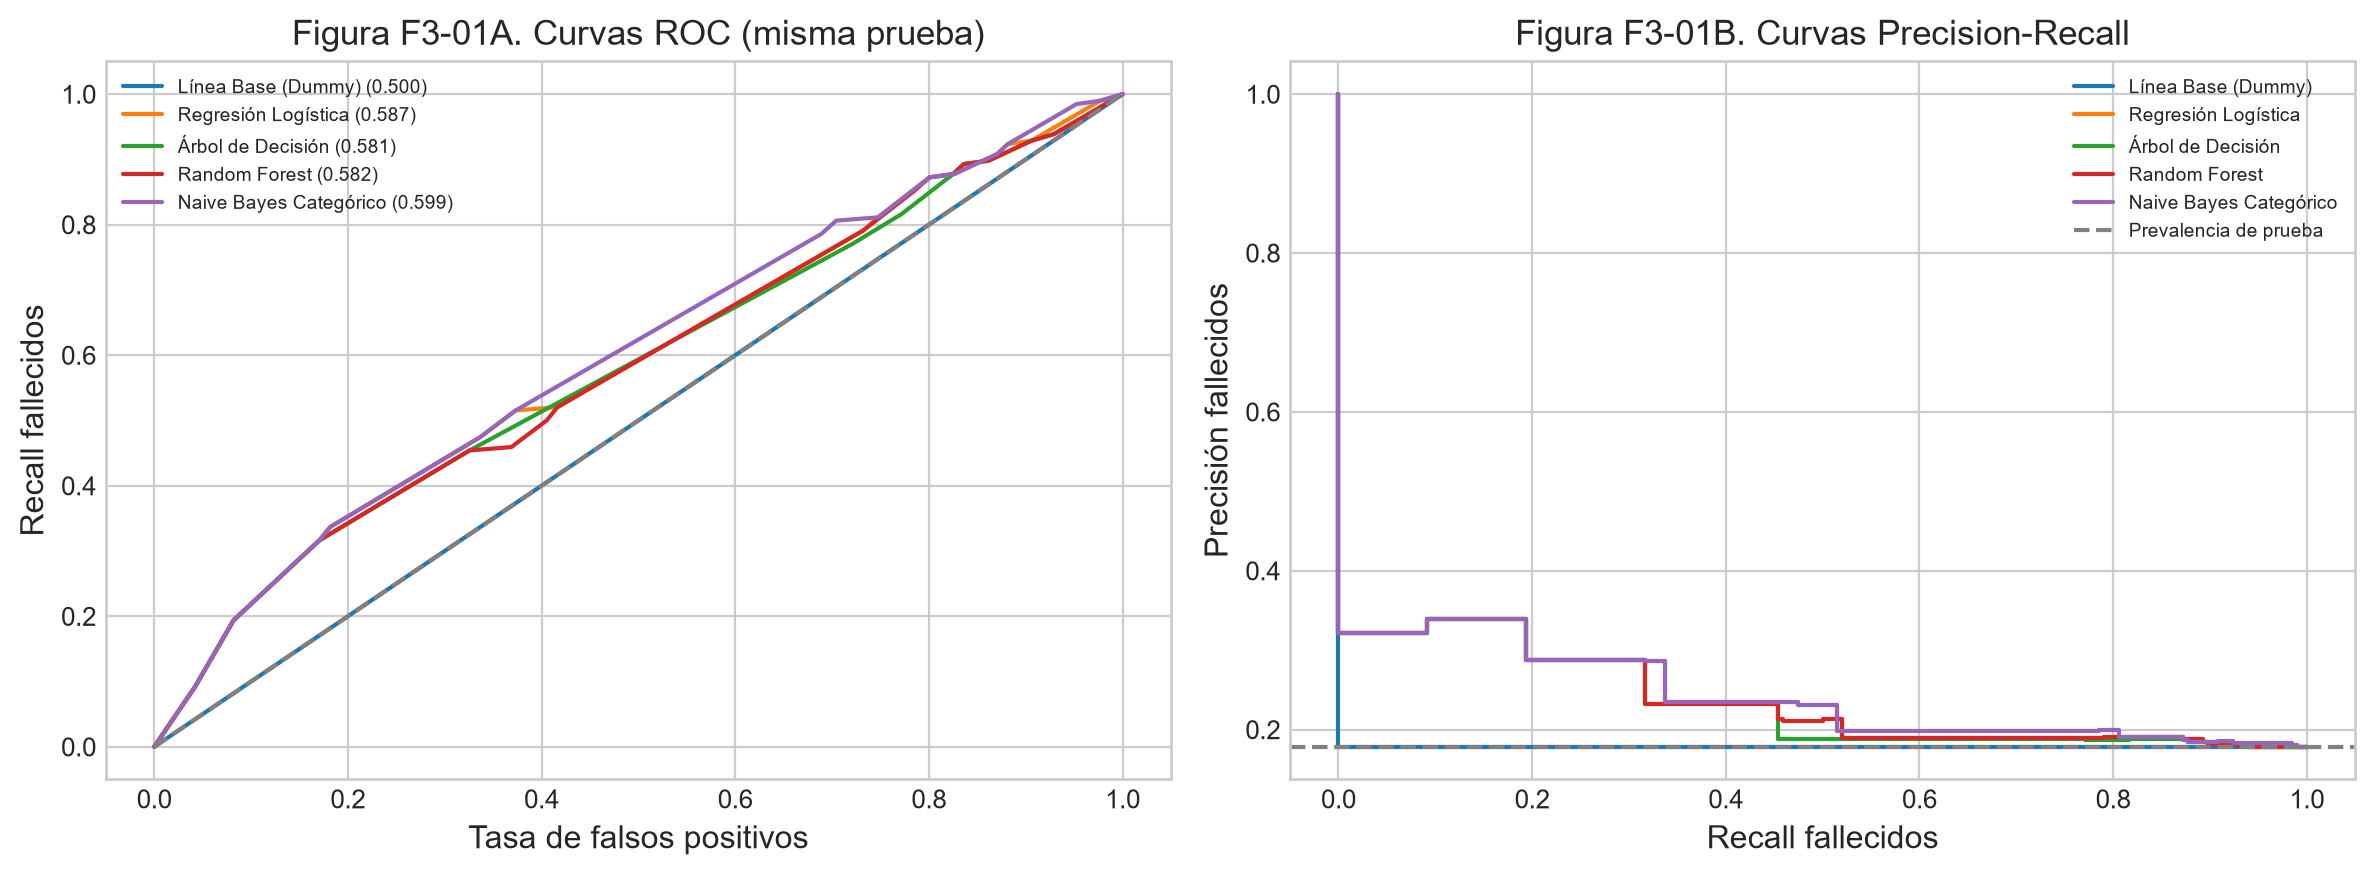

**Interpretación:** Las curvas comparan los mismos 1.099 registros expandidos. AUC y Precision-Recall describen discriminación interna; la línea PR corresponde a la prevalencia de esa reserva. La tabla de métricas permite comprobar las diferencias sin atribuir superioridad externa.

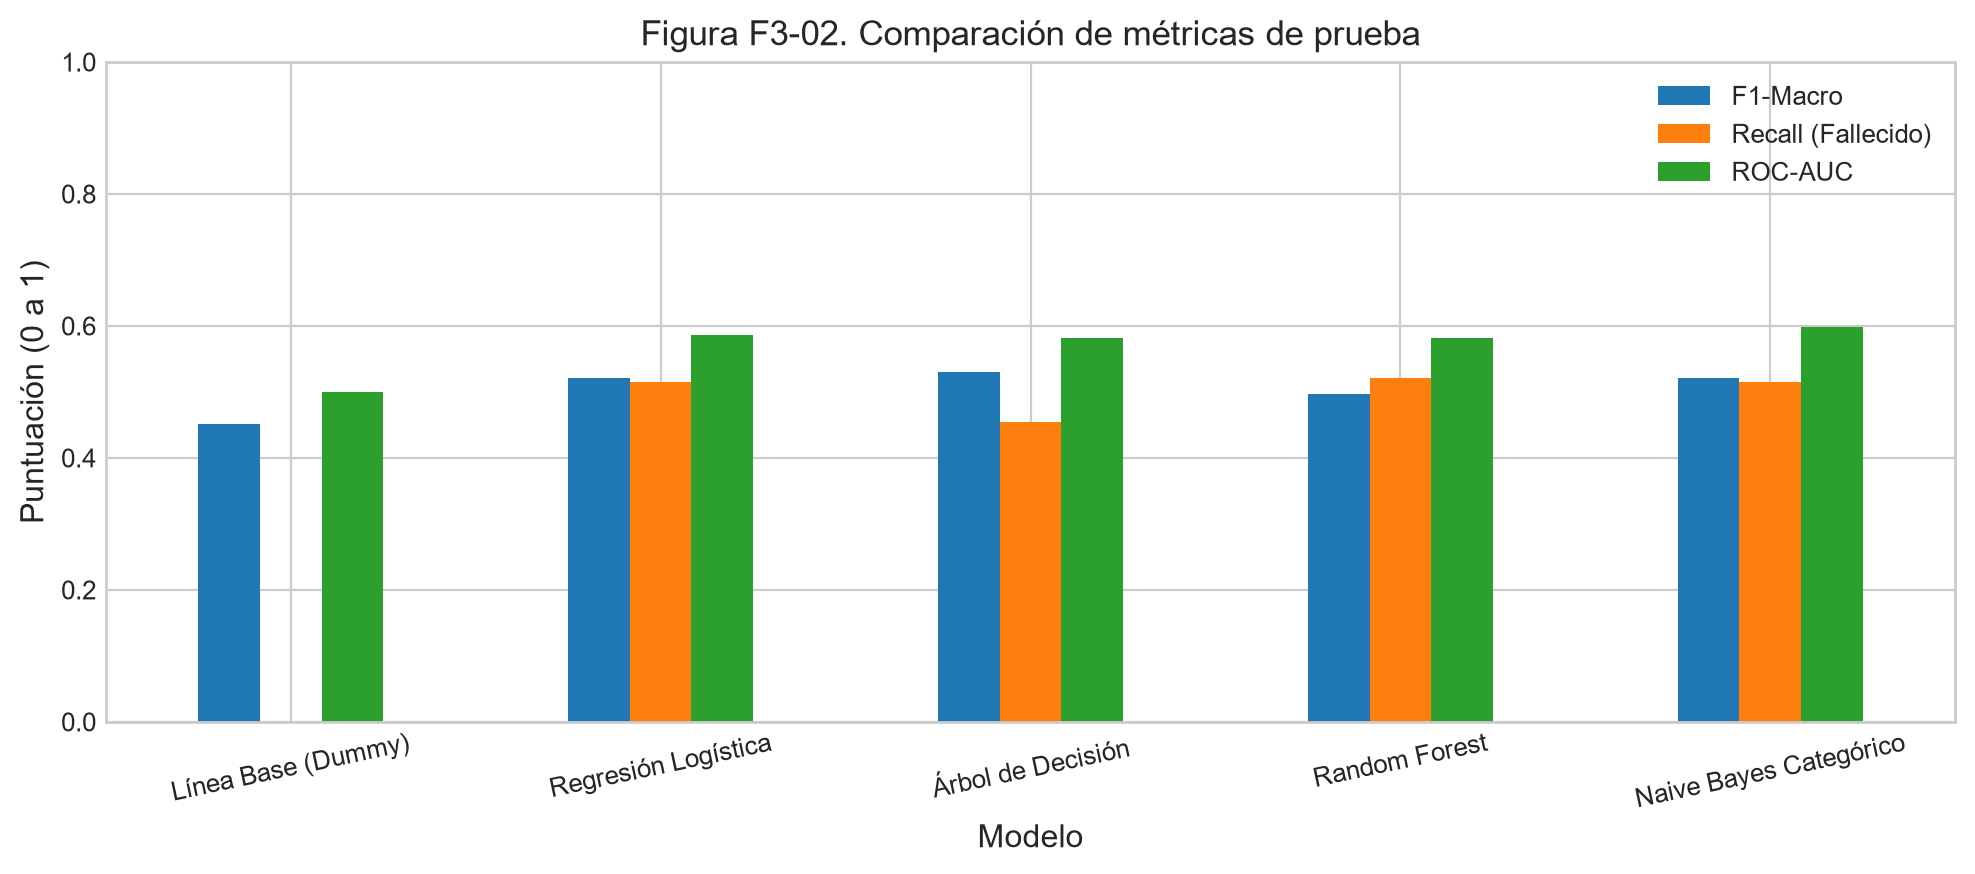

**Interpretación:** El árbol se elige por CV, aunque otro candidato pueda tener AUC de prueba mayor. La mejora de F1 macro frente a Dummy no implica mejor calibración ni una regla clínica.

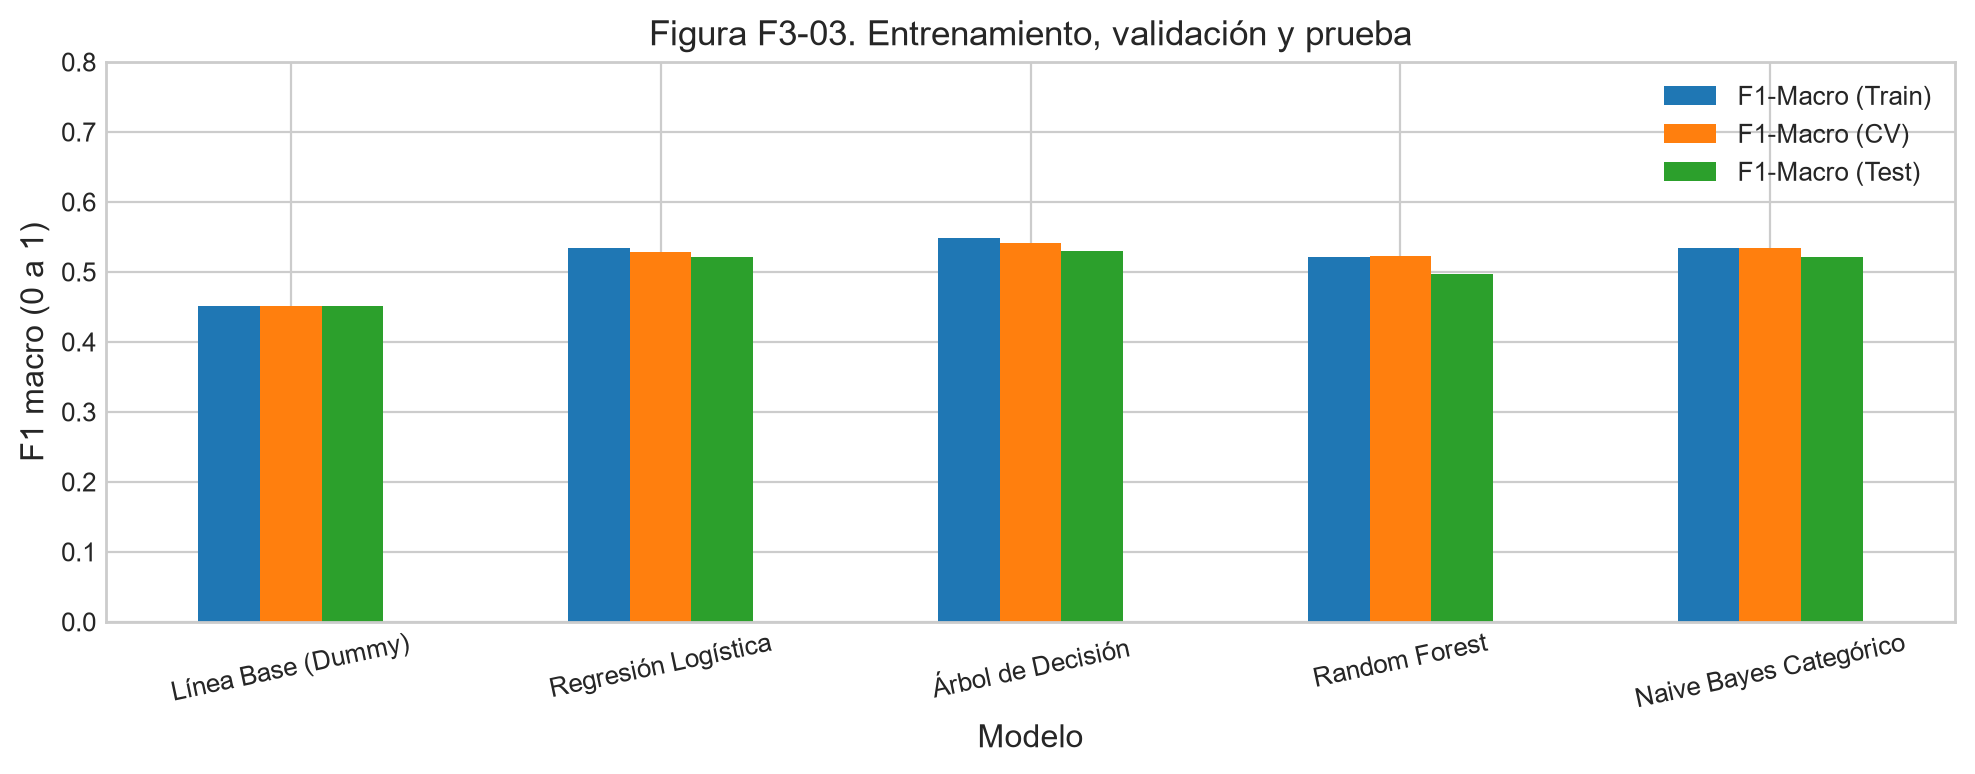

**Interpretación:** Las brechas se cuantifican en las tablas. Su tamaño pequeño está condicionado por perfiles repetidos y por la selección dentro de CV; no acredita generalización externa.

In [7]:
# Diagnósticos calculados una sola vez y devueltos explícitamente.
modelos_evaluados = {'Línea Base (Dummy)': dummy_baseline, **modelos_optimizados}
tablas_extra, predicciones_prueba, solapamiento_FN, equivalencia_frecuencias = calcular_diagnosticos(
    modelos_evaluados, nombre_mejor_modelo, X_train_d, y_train_d, X_test_d, y_test_d,
    predicciones_test, df_reporte_cv, df_brechas)
# Reutilizamos los mismos cuatro pliegues del ganador, sin volver a entrenarlo.
df_sensibilidad = (tablas_extra['sensibilidad_todos']
    .loc[lambda d: d.Modelo.eq(nombre_mejor_modelo), ['pliegue', 'F1_macro', 'AUC_ROC']]
    .rename(columns={'pliegue': 'Pliegue'}).reset_index(drop=True))
display(tablas_extra['comparacion_etapas'].rename(columns={'Brecha Absoluta': 'Diferencia train − test'}).round(4))
mostrar_complementos(['F3-01', 'F3-02', 'F3-03'], tablas_extra, predicciones_test, y_test_d, df_resultados_test)

In [8]:
sel = df_resultados_test.loc[nombre_mejor_modelo]
base = df_resultados_test.loc['Línea Base (Dummy)']
display(Markdown(
    f"**Lectura:** {nombre_mejor_modelo} gana por CV, no por test. F1 macro de reserva "
    f"{sel['F1-Macro']:.4f} frente a {base['F1-Macro']:.4f} del Dummy; "
    f"recall fallecidos {sel['Recall (Fallecido)']:.2%}, AUC {sel['ROC-AUC']:.4f}. "
    f"Dummy tiene mejor accuracy ({base['Accuracy']:.4f}) y Brier ({base['Brier']:.4f}), "
    "pero omite todos los fallecidos. La mejora es interna y limitada."))

**Lectura:** Árbol de Decisión gana por CV, no por test. F1 macro de reserva 0.5299 frente a 0.4510 del Dummy; recall fallecidos 45.41%, AUC 0.5809. Dummy tiene mejor accuracy (0.8217) y Brier (0.1783), pero omite todos los fallecidos. La mejora es interna y limitada.

## 5. Errores: qué significa omitir una fatalidad
La matriz separa aciertos y errores. **FN** es un fallecido clasificado herido; **FP**, un herido clasificado fallecido. No son decisiones clínicas: son resultados retrospectivos sobre frecuencias.

Cada perfil recibe el mismo puntaje y clase; el modelo no conoce velocidad, protección, lesión o atención para distinguir circunstancias dentro del perfil. Se muestran primero la matriz del ganador y los peores perfiles; luego la comparación de todos y los errores por subgrupos.

El residuo absoluto de un puntaje compara desenlace 0/1 y puntuación; no explica la causa individual. Para presentar los perfiles se redondea el puntaje a cuatro decimales, como en la versión anterior.

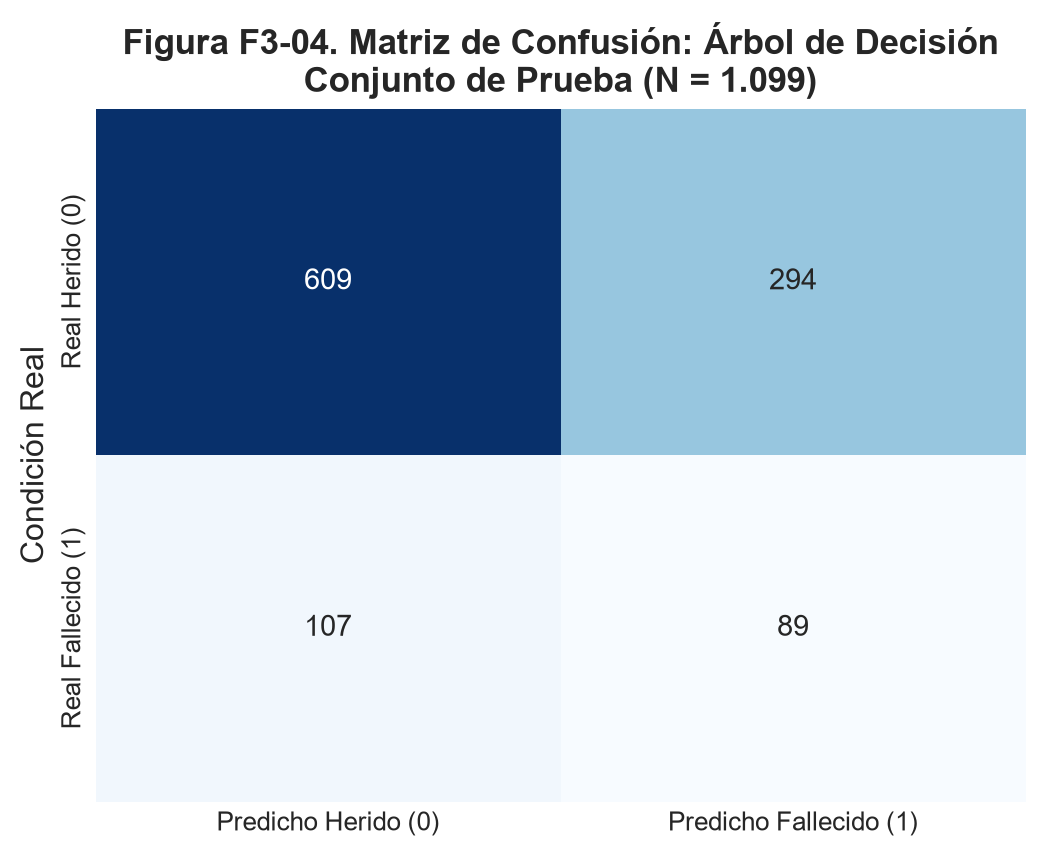

TABLA 4: PERFILES CON MAYOR RESIDUO DE ERROR EN EL CONJUNTO DE PRUEBA


,sexo,grupo_edad,Real,Predicho,Prob_Fallecido,Error_Absoluto,Tipo_Error
4903,Hombre,De 60 anos y mas,0,1,0.7391,0.7391,Falso Positivo (Falsa Alarma)
2876,Mujer,De 18 a 29 anos,1,0,0.2749,0.7251,Falso Negativo (Omisión de Fatalidad)
753,Mujer,De 14 a 17 anos,1,0,0.2822,0.7178,Falso Negativo (Omisión de Fatalidad)
3826,Mujer,De 30 a 39 anos,1,0,0.3457,0.6543,Falso Negativo (Omisión de Fatalidad)
4647,Hombre,De 50 a 59 anos,0,1,0.6541,0.6541,Falso Positivo (Falsa Alarma)
4460,Mujer,De 40 a 49 anos,1,0,0.3721,0.6279,Falso Negativo (Omisión de Fatalidad)
5489,Mujer,Ignorado,1,0,0.3765,0.6235,Falso Negativo (Omisión de Fatalidad)
711,Hombre,De 14 a 17 anos,1,0,0.4075,0.5925,Falso Negativo (Omisión de Fatalidad)


In [9]:
# 1. Matriz de Confusión
pred_opt = predicciones_test[nombre_mejor_modelo]['clase']
prob_demog_opt = predicciones_test[nombre_mejor_modelo]['puntaje']
cm = tablas_extra['matrices'].loc[nombre_mejor_modelo, ['TN', 'FP', 'FN', 'TP']].to_numpy().reshape(2, 2)

fig_cm, ax_cm = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Predicho Herido (0)', 'Predicho Fallecido (1)'],
            yticklabels=['Real Herido (0)', 'Real Fallecido (1)'])
ax_cm.set_title(f"Figura F3-04. Matriz de Confusión: {nombre_mejor_modelo}\nConjunto de Prueba (N = 1.099)", fontweight='bold')
ax_cm.set_ylabel("Condición Real")

plt.show()

# 2. Extracción sistemática de los casos peor predichos
df_analisis_error = X_test_d.copy()
df_analisis_error['Real'] = y_test_d
df_analisis_error['Predicho'] = pred_opt
df_analisis_error['Prob_Fallecido'] = prob_demog_opt.round(4)
df_analisis_error['Error_Absoluto'] = np.abs(df_analisis_error['Real'] - df_analisis_error['Prob_Fallecido'])

condiciones = [
    (df_analisis_error['Real'] == 1) & (df_analisis_error['Predicho'] == 0),
    (df_analisis_error['Real'] == 0) & (df_analisis_error['Predicho'] == 1)
]
etiquetas = ['Falso Negativo (Omisión de Fatalidad)', 'Falso Positivo (Falsa Alarma)']
df_analisis_error['Tipo_Error'] = np.select(condiciones, etiquetas, default='Acierto')

# Casos con mayor residuo de probabilidad
peores_fallos = (df_analisis_error[df_analisis_error['Tipo_Error'] != 'Acierto']
                 .sort_values(by='Error_Absoluto', ascending=False)
                 .drop_duplicates(subset=['sexo', 'grupo_edad', 'Tipo_Error']))

print("=" * 95)
print("TABLA 4: PERFILES CON MAYOR RESIDUO DE ERROR EN EL CONJUNTO DE PRUEBA")
print("=" * 95)
display(peores_fallos[['sexo', 'grupo_edad', 'Real', 'Predicho', 'Prob_Fallecido', 'Error_Absoluto', 'Tipo_Error']].head(8))

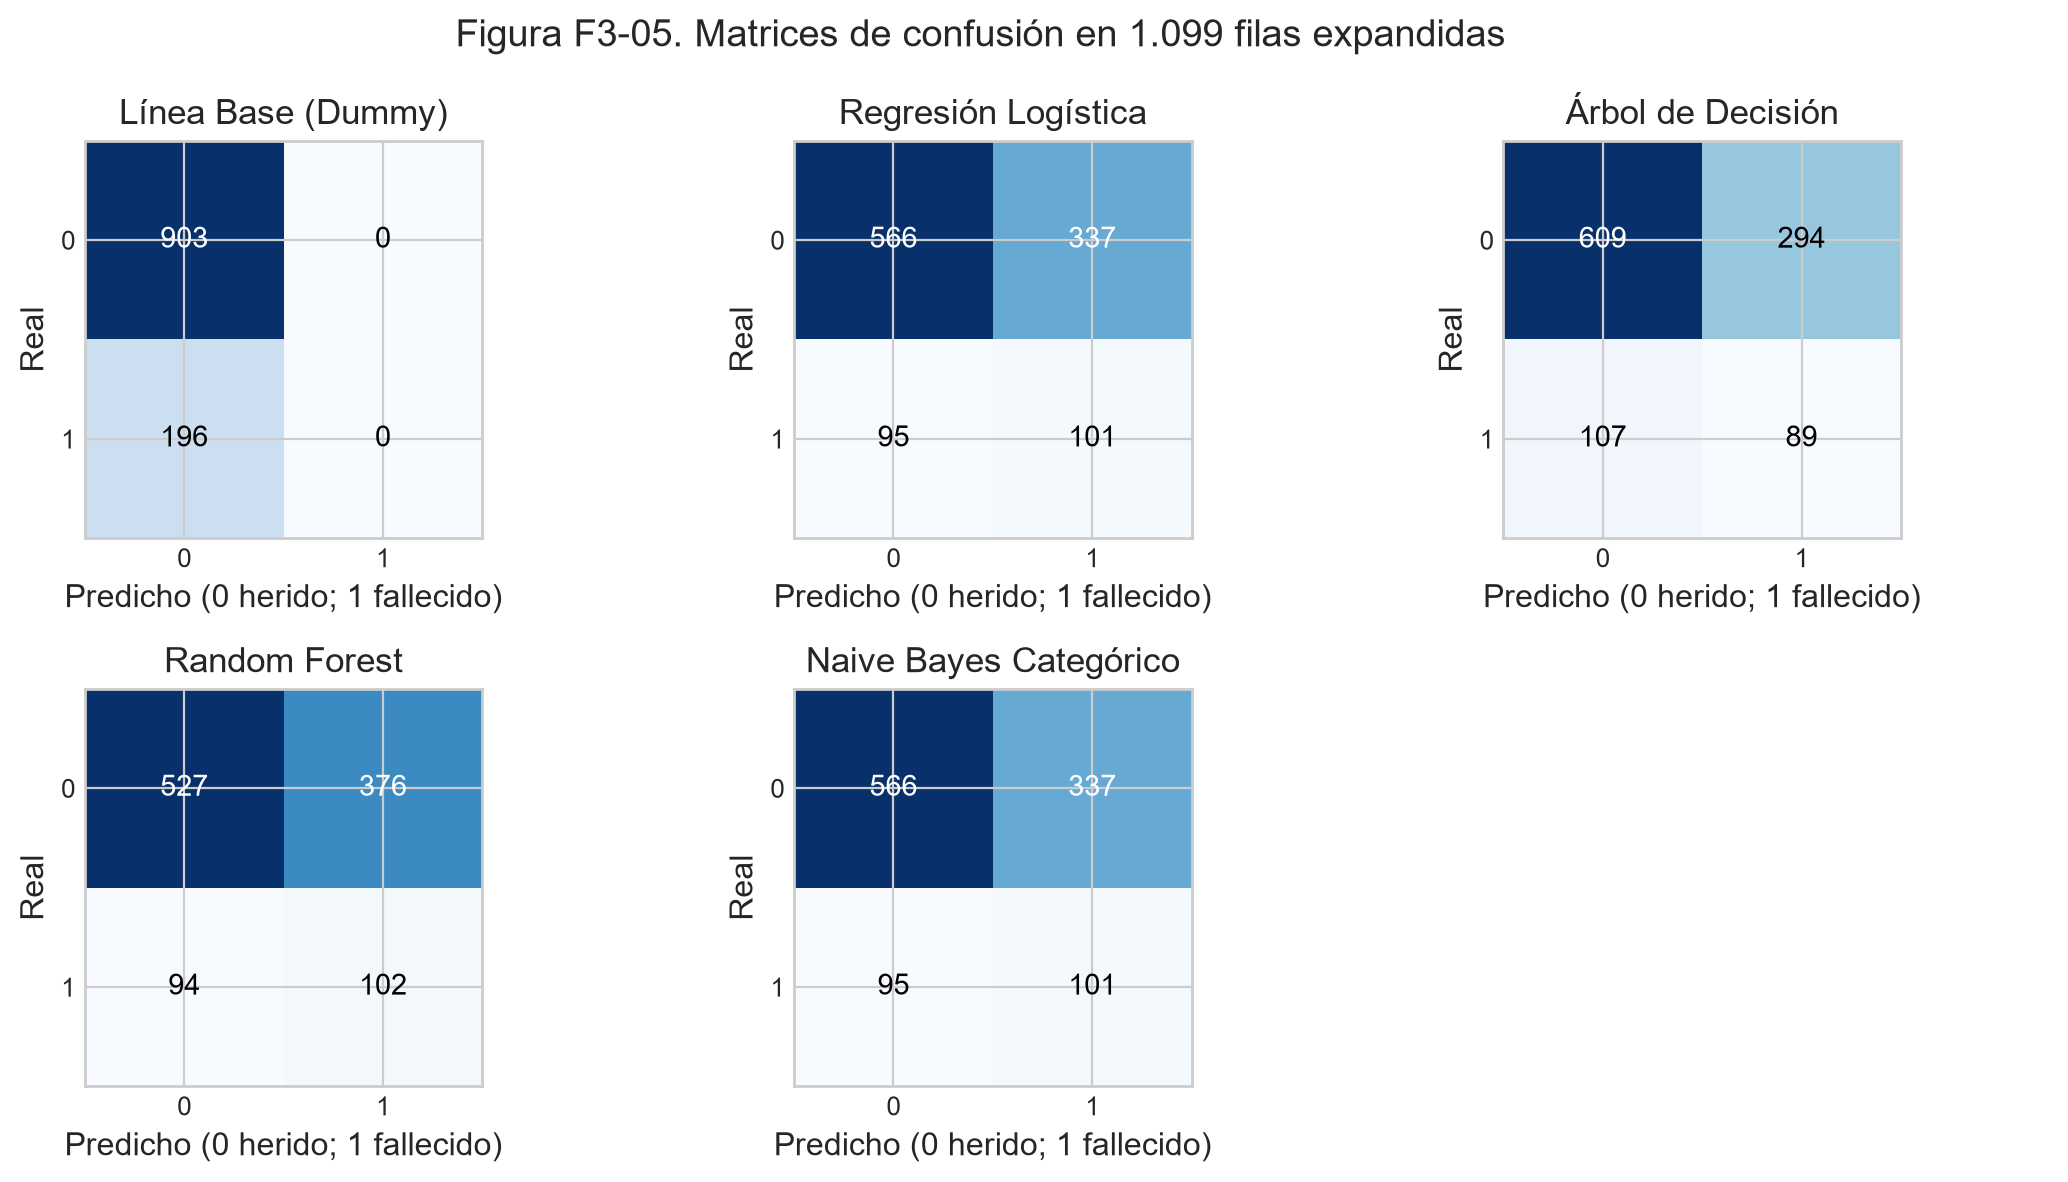

**Interpretación:** Dummy no identifica ninguna fatalidad. Cada matriz permite contrastar omisiones y falsas alarmas con denominadores idénticos; 0 = herido y 1 = fallecido. La diagonal contiene aciertos y las otras celdas errores.

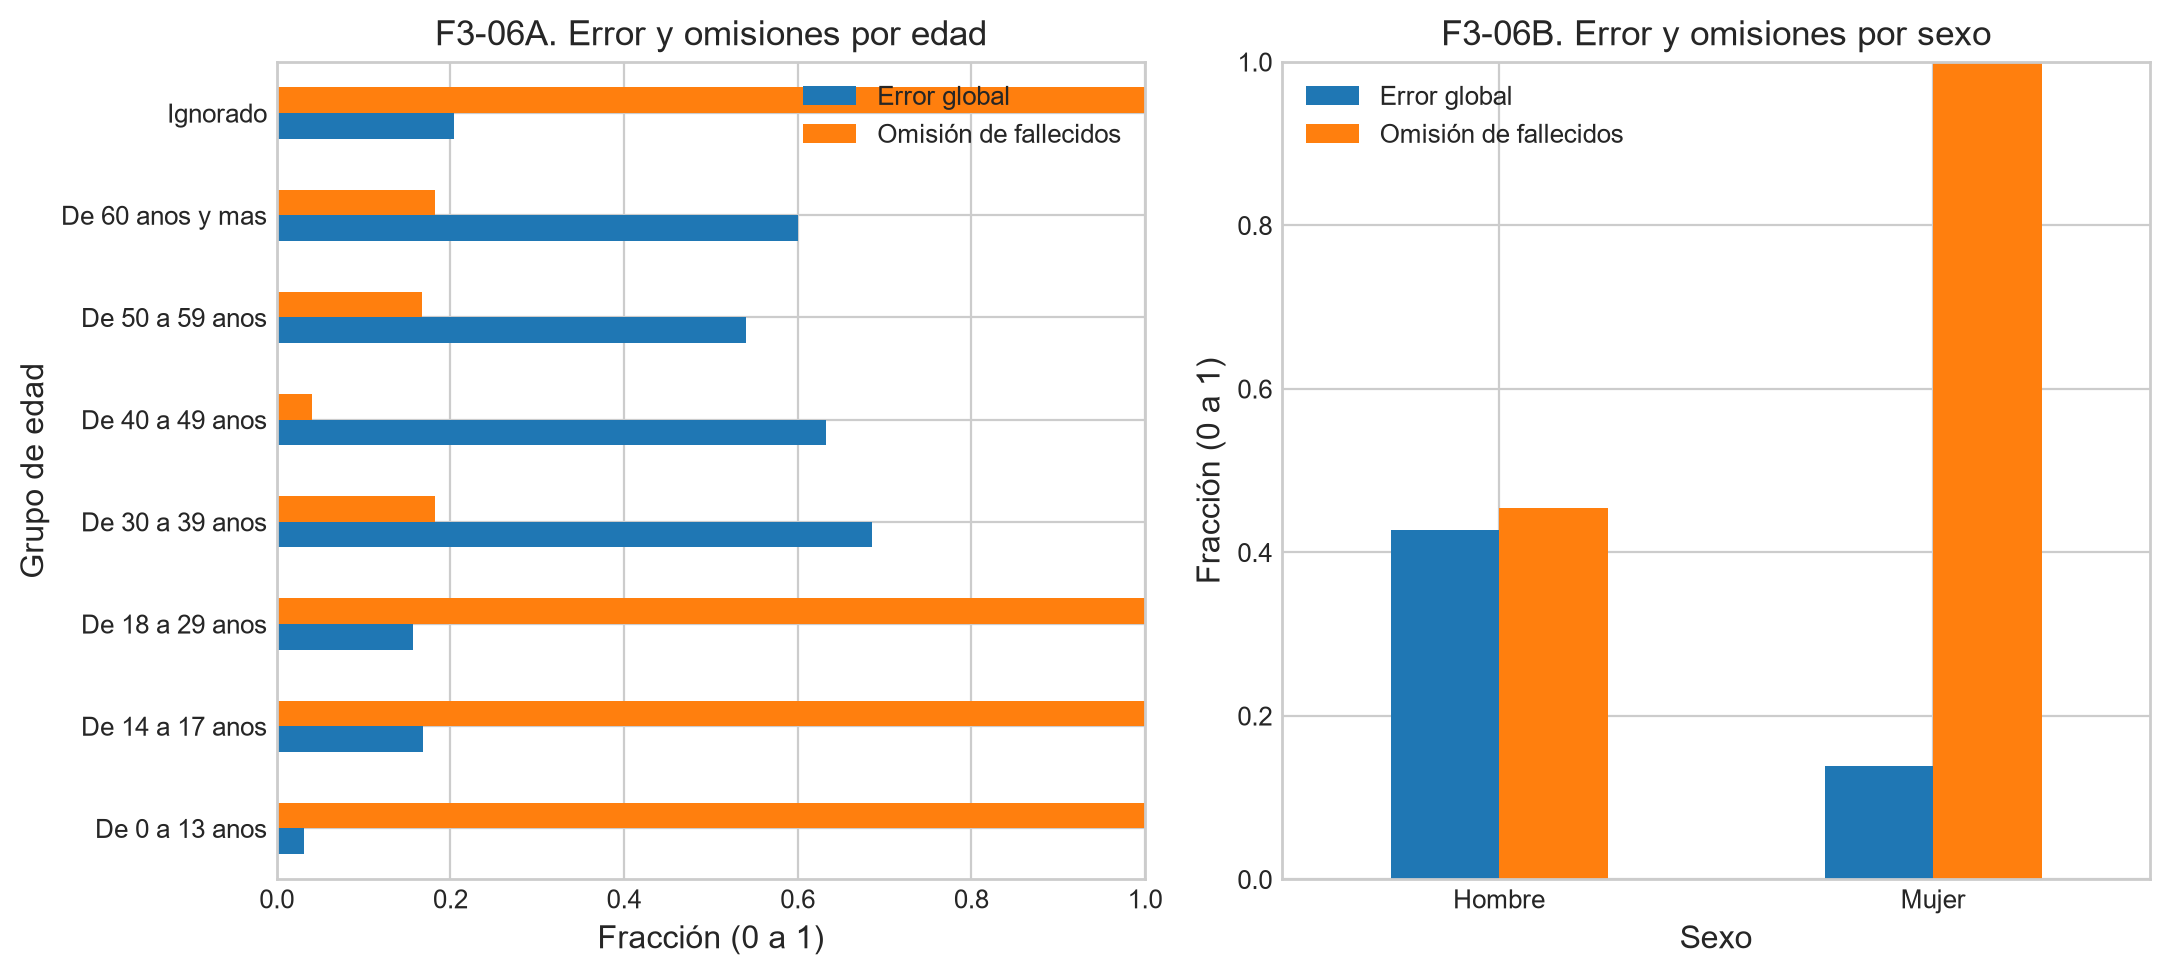

**Interpretación:** La tasa de error divide por todas las filas del grupo; la tasa FN divide solo por sus fallecidos. En particular, el seleccionado no detecta fatalidades entre mujeres de esta reserva y omite las de varios grupos jóvenes. Una tasa global pequeña puede coexistir con omisión total de la clase minoritaria.

,Sexo,Tramo,FN
0,Hombre,0-29 años,66
1,Hombre,30 años o más,0
2,Hombre,Edad ignorada,8
3,Mujer,0-29 años,15
4,Mujer,30 años o más,15
5,Mujer,Edad ignorada,3


,n,fallecidos,FN,FP,TP,TN,errores,residuo_medio,tasa_error,recall_fallecidos,tasa_FN
sexo,,,,,,,,,,,
Hombre,862,163,74,294,89,405,368,0.5110,0.4269,0.546,0.454
Mujer,237,33,33,0,0,204,33,0.3852,0.1392,0.000,1.000


**Lectura de los errores:** TN=609, FP=294, FN=107, TP=89. Se detectan 89 de 196 fallecidos. Las 33 omisiones entre mujeres y las 81 de 0–29 años se superponen en 15: 33+81−15=99; restan 8 hombres de edad ignorada. La tasa global de error divide por todas las víctimas del grupo; la tasa FN solo por sus fallecidos. Las mujeres tienen recall de fallecidos cero en esta reserva. Dar peso a una clase no garantiza equidad entre perfiles.

In [10]:
mostrar_complementos(['F3-05', 'F3-06'], tablas_extra, predicciones_test, y_test_d, df_resultados_test)
display(tablas_extra['descomposicion_FN'])
display(tablas_extra['errores_sexo'].round(4))
s = solapamiento_FN
cm_ganador = tablas_extra['matrices'].loc[nombre_mejor_modelo]
display(Markdown(
    f"**Lectura de los errores:** TN={int(cm_ganador.TN)}, FP={int(cm_ganador.FP)}, "
    f"FN={int(cm_ganador.FN)}, TP={int(cm_ganador.TP)}. Se detectan "
    f"{int(cm_ganador.TP)} de {int(cm_ganador.FN+cm_ganador.TP)} fallecidos. "
    f"Las {s['mujeres']} omisiones entre mujeres y las {s['edades_0_29']} de 0–29 años "
    f"se superponen en {s['interseccion']}: {s['mujeres']}+{s['edades_0_29']}−"
    f"{s['interseccion']}={s['union']}; restan {s['restantes']} hombres de edad ignorada. "
    "La tasa global de error divide por todas las víctimas del grupo; la tasa FN solo por sus fallecidos. "
    "Las mujeres tienen recall de fallecidos cero en esta reserva. Dar peso a una clase no garantiza equidad entre perfiles."))

## 6. Interpretación: asociación e importancia no son causalidad
**Coeficientes logísticos:** se interpretan respecto de Hombre y 0–13 años. El signo muestra dirección en el modelo; `exp(beta)` es un OR condicionado por las otras variables, regularizado y entrenado con ponderación. No es una razón de riesgos ni una nueva prueba inferencial.

**Gini:** distribuye la reducción de impureza entre indicadores. Se suman los indicadores de edad para compararlos con sexo. **Permutación:** desordena una columna y mide la caída de F1 macro; media y desvío provienen de 30 permutaciones, no de un IC poblacional. Una variable predictiva no es necesariamente una causa.

TABLA 5: COEFICIENTES ESTIMADOS POR LA REGRESIÓN LOGÍSTICA DEMOGRÁFICA


,Atributo Codificado,Coeficiente Beta,Odds Ratio (e^Beta)
0,grupo_edad_De 60 anos y mas,1.1296,3.0945
1,grupo_edad_De 50 a 59 anos,0.6549,1.9250
2,grupo_edad_De 40 a 49 anos,0.3825,1.4660
3,grupo_edad_De 30 a 39 anos,0.2376,1.2682
4,grupo_edad_Ignorado,0.1386,1.1486
5,grupo_edad_De 18 a 29 anos,-0.0165,0.9837
6,grupo_edad_De 14 a 17 anos,-0.2703,0.7631
7,sexo_Mujer,-0.7932,0.4524


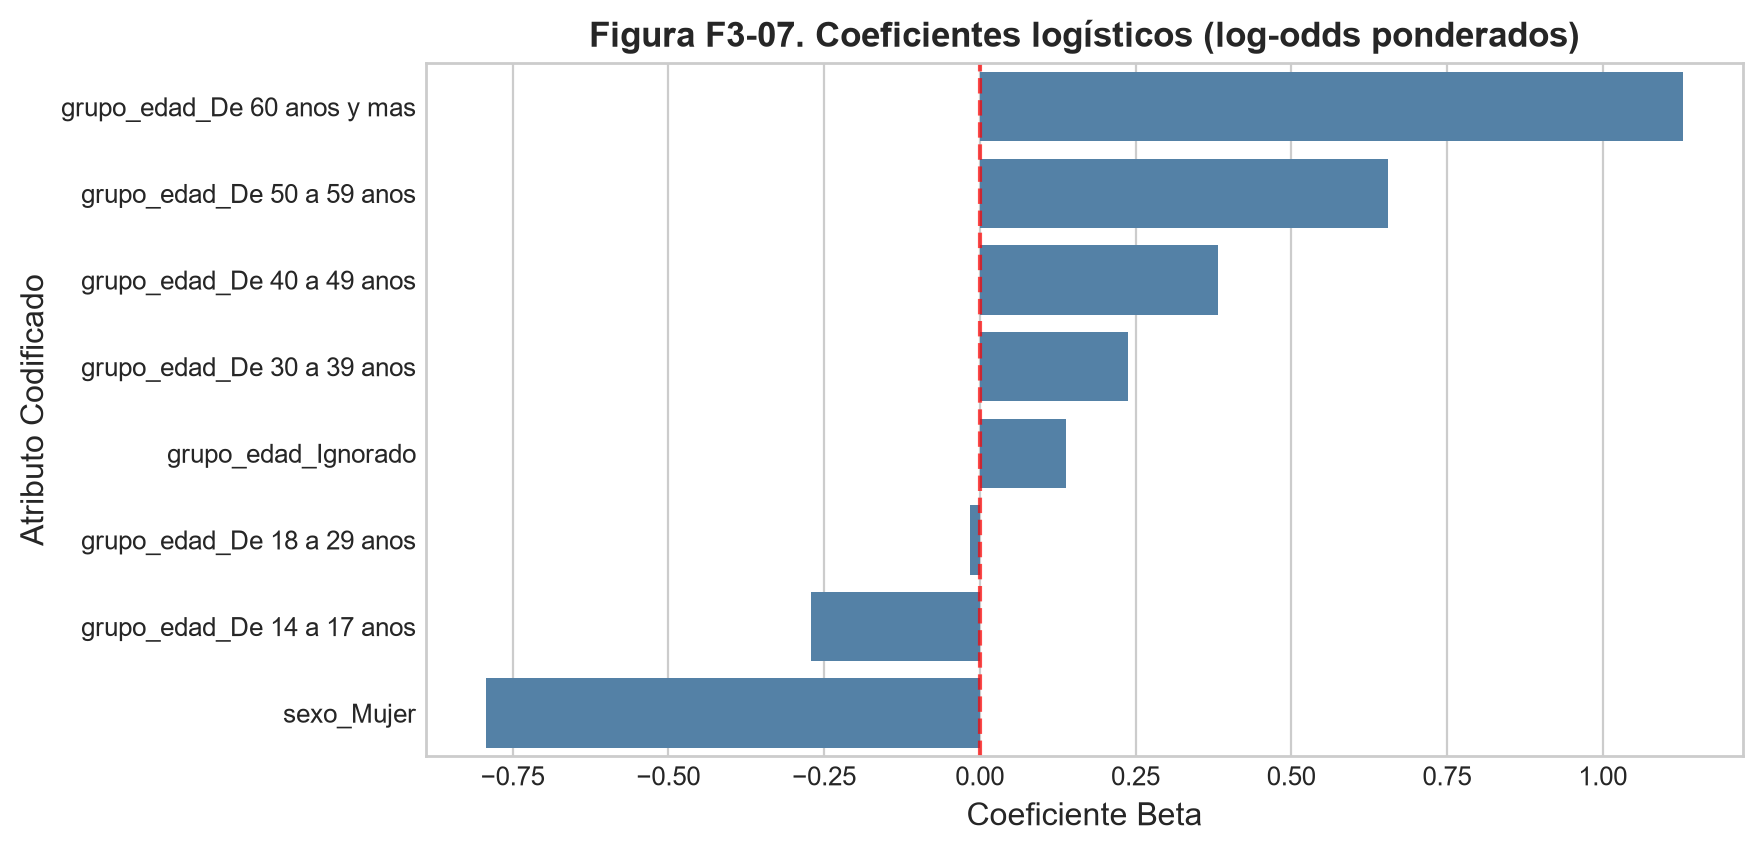

Referencias del encoder: {'sexo': 'Hombre', 'grupo_edad': 'De 0 a 13 anos'}


In [11]:
# Extracción de coeficientes de la Regresión Logística
pipeline_lr = modelos_optimizados["Regresión Logística"]
codificador_ohe = pipeline_lr.named_steps['prep'].named_transformers_['cat']
nombres_ohe = codificador_ohe.get_feature_names_out(columnas_categoricas).tolist()

coeficientes = pipeline_lr.named_steps['clf'].coef_[0]
odds_ratios = np.exp(coeficientes)

df_coef = pd.DataFrame({
    "Atributo Codificado": nombres_ohe,
    "Coeficiente Beta": coeficientes,
    "Odds Ratio (e^Beta)": odds_ratios
}).sort_values(by="Coeficiente Beta", ascending=False).reset_index(drop=True)

print("=" * 80)
print("TABLA 5: COEFICIENTES ESTIMADOS POR LA REGRESIÓN LOGÍSTICA DEMOGRÁFICA")
print("=" * 80)
display(df_coef.round(4))

# Visualización
fig_coef, ax_coef = plt.subplots(figsize=(8.5, 4.5))
sns.barplot(data=df_coef, x="Coeficiente Beta", y="Atributo Codificado", color="steelblue", ax=ax_coef)
ax_coef.axvline(0, color='red', linestyle='--', alpha=0.7)
ax_coef.set_title("Figura F3-07. Coeficientes logísticos (log-odds ponderados)", fontweight='bold')
ax_coef.set_xlabel("Coeficiente Beta")

plt.show()
print('Referencias del encoder:', dict(zip(columnas_categoricas, [c[0] for c in codificador_ohe.categories_])))

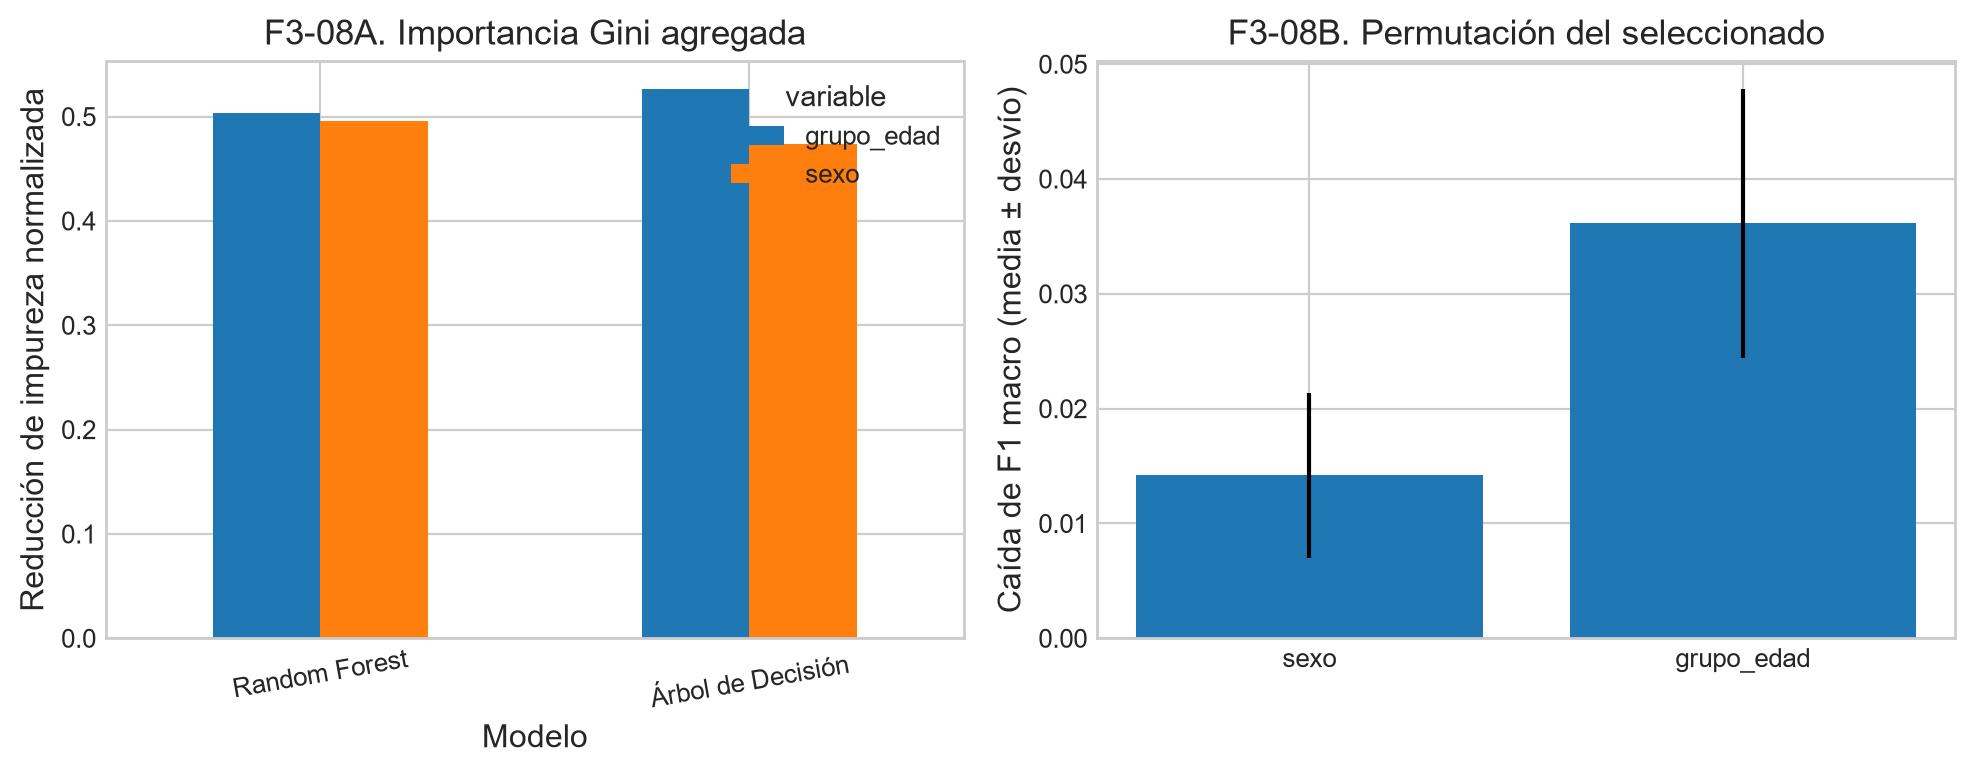

**Interpretación:** Gini agrega la reducción de impureza de los indicadores de cada variable. La permutación mide caída de F1 macro al desordenar la columna completa; sus barras muestran variación entre permutaciones. No representan causalidad ni intervalos poblacionales.

variable,grupo_edad,sexo
Modelo,,
Random Forest,0.5038,0.4962
Árbol de Decisión,0.5267,0.4733


,variable,media,desvio
0,sexo,0.0142,0.0072
1,grupo_edad,0.0361,0.0117


In [12]:
mostrar_complementos(['F3-08'], tablas_extra, predicciones_test, y_test_d, df_resultados_test)
display(tablas_extra['gini_variables'].round(4))
display(tablas_extra['permutacion'].round(4))

### 6.1. Sobreajuste, perfiles no vistos y calibración
Una brecha pequeña entre train y reserva no demuestra generalización: las mismas combinaciones sexo × edad se repiten. **GroupKFold** mantiene cada perfil completo en un solo lado del pliegue, usando solo train y los hiperparámetros ya elegidos. Se calcula una vez para todos los candidatos. No es validación anidada ni prueba externa en personas futuras.

Los pliegues no tienen los mismos tamaños ni cantidad de perfiles; uno contiene un solo perfil y entonces todos reciben igual puntaje. Una AUC de 0,5 en ese pliegue es esperable. Categorías ausentes pueden activar advertencias del codificador; no se ocultan.

**Calibración:** comparar puntaje medio y fracción observada permite detectar discrepancias. Ponderar clases puede acercar puntajes a 0,5 aunque la prevalencia sea ≈0,178. No se ajusta un calibrador o umbral con test. Brier y las curvas se conservan aunque sean desfavorables.

,Pliegue,F1_macro,AUC_ROC
0,1,0.4536,0.5000
1,2,0.4449,0.4451
2,3,0.3910,0.5669
3,4,0.5328,0.5872


Sensibilidad del ganador: {'F1_macro': 0.4556, 'AUC_ROC': 0.5248}
Frecuencia real / puntuación media: 0.1783 0.4902


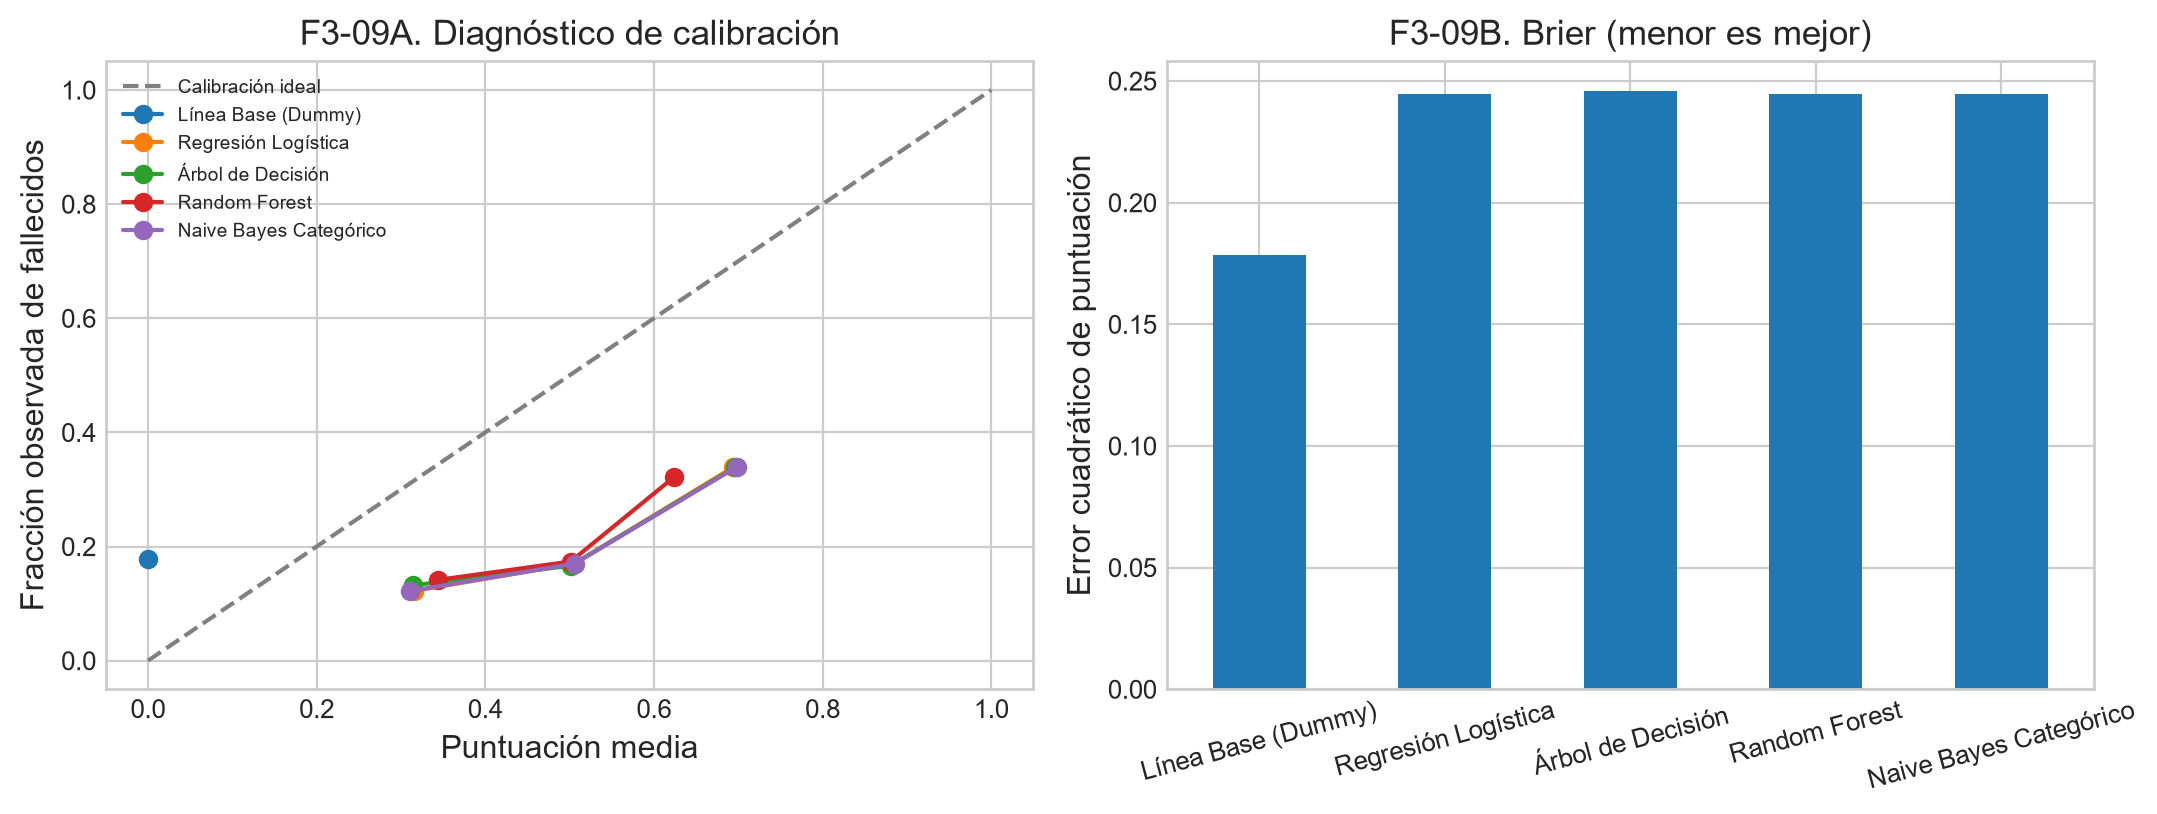

**Interpretación:** La distancia a la diagonal revela discrepancias entre puntuaciones y frecuencia observada. Brier debe compararse con la base, incluso si el modelo mejora F1. No se ajusta calibración en test y no se informa riesgo individual real.

Equivalencia expansión/frecuencias ponderadas: {'celdas_train': 32, 'max_diferencia_puntuacion': 6.661338147750939e-16, 'tolerancia_numerica': 0.002, 'interpretacion': 'La expansión no aporta información adicional a los conteos.'}


In [13]:
display(df_sensibilidad.round(4))
print('Sensibilidad del ganador:', df_sensibilidad[['F1_macro', 'AUC_ROC']].mean().round(4).to_dict())
print('Frecuencia real / puntuación media:', round(float(np.mean(y_test_d)),4),
      round(float(predicciones_test[nombre_mejor_modelo]['puntaje'].mean()),4))
mostrar_complementos(['F3-09'], tablas_extra, predicciones_test, y_test_d, df_resultados_test)
print('Equivalencia expansión/frecuencias ponderadas:', equivalencia_frecuencias)
# Este ajuste logístico adicional usa solo train y demuestra equivalencia de información;
# no es una validación independiente ni un candidato nuevo para selección.

## 7. Hipótesis H1–H4: fuentes separadas, preguntas complementarias
Los análisis siguientes no cambian los predictores, la partición ni el modelo seleccionado. La inferencia pregunta por asociaciones; la predicción compara clases y puntajes. No se estima el efecto simultáneo de los cuatro factores.

`complementos_auditados()` ejecuta los contrastes corregidos de edad y la evaluación territorial descritos debajo. `preparar_contexto()` coteja fuentes y reúne los antecedentes históricos. Se pasan los análisis explícitamente para no recalcularlos. La independencia por siniestro y los sesgos de registro no son comprobables con estas tablas.

In [14]:
analisis_hipotesis = complementos_auditados(df_demografico, Path(BASE_DIR))
tablas_contexto, tabla_vehicular, auditoria_contexto = preparar_contexto(Path(BASE_DIR), analisis=analisis_hipotesis)

### 7.1. H1 — Territorio y evaluación binomial
Primero se describen tasas de 12.2.6: fallecidos / víctimas registradas en cada zona. Metropolitana suma Asunción y Central. El chi-cuadrado y OR Interior/Metropolitana se recuperan de Fase 2 como antecedentes, sin volver a buscar cortes significativos.

El CSV original también permite **36 celdas: 12 meses × 3 zonas**. El GLM binomial recibe dos conteos `[fallecidos, heridos]` por celda, sin expandir supuestas personas. Usa intercepto y dos indicadores de zona; Asunción es la referencia. Sin otros predictores, estima tasas por zona.

**Validación cronológica:** meses 1–6 → 7–8; 1–8 → 9–10; 1–10 → 11–12. El mes define el corte, no entra como predictor: un ciclo anual no permite justificar estacionalidad. La base predice la tasa global aprendida solo de meses anteriores.

Log-loss penaliza puntajes incompatibles con los conteos, Brier mide error cuadrático por víctima y MAE compara proporciones con ponderación por tamaño de celda. Menor es mejor. No son métricas intercambiables con las del clasificador nacional.

Los coeficientes finales usan los doce meses para descripción; no son un único ajuste usado para todos los bloques. OR Central/Asunción e Interior/Asunción no equivalen al OR histórico Interior/Metropolitana. El OR del intercepto es la odds de referencia, no un efecto causal.

,heridos,fallecidos,total_victimas,tasa_fallecidos_pct
zona,,,,
Asunción,141,26,167,15.5689
Central,394,82,476,17.2269
Interior,661,187,848,22.0519


**Lectura de la tabla:** cada denominador es el total de víctimas de su zona, no población expuesta ni cantidad de accidentes. Heridos + fallecidos coincide con el total.

,heridos,fallecidos,total_victimas,tasa_fallecidos_pct
grupo,,,,
Metropolitana,535,108,643,16.7963
Interior,661,187,848,22.0519


**Agrupación histórica H1:** Metropolitana suma Asunción y Central. Se conserva esa definición para recuperar el contraste de Fase 2; no se interpreta como prueba de todas las diferencias entre las tres zonas.

,prueba_aplicada,estadístico,p_valor_crudo,p_valor_ajustado_bonferroni,tamaño_del_efecto
hipótesis,,,,,
H1,Chi-cuadrado de independencia,χ² = 6.3647 (gl = 1),0.011641,0.046565,OR = 1.4014; V de Cramér = 0.0653


**Antecedente:** se informa el p ajustado junto con el efecto. No se recalcula el contraste ni se trasladan sus resultados al problema predictivo demográfico.

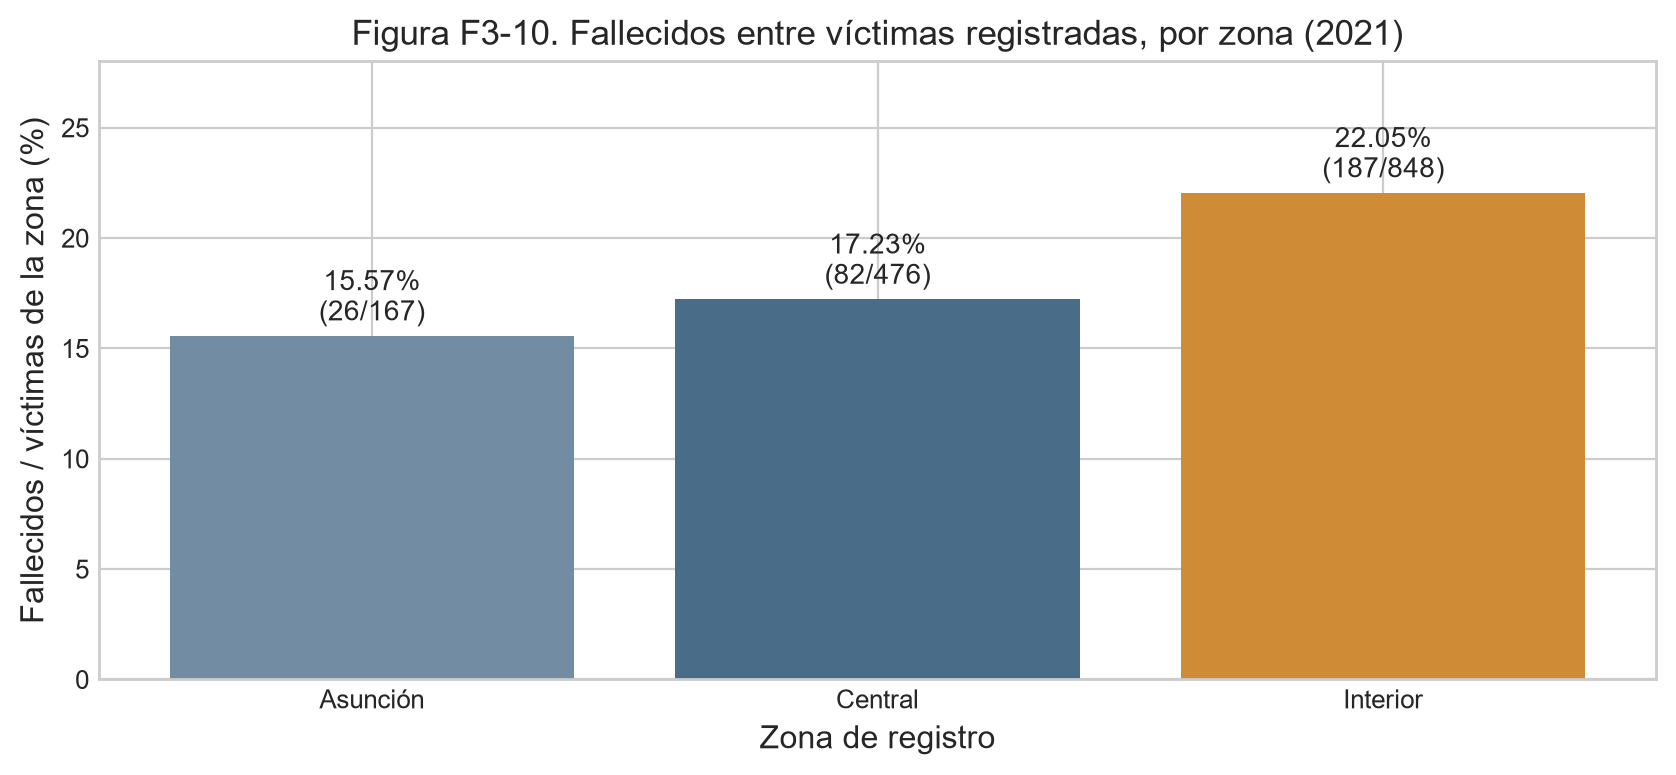

In [15]:
territorio = tablas_contexto['territorio']
display(territorio.round(4))
display(Markdown('**Lectura de la tabla:** cada denominador es el total de víctimas de su zona, no población expuesta ni cantidad de accidentes. Heridos + fallecidos coincide con el total.'))
display(tablas_contexto['territorio_h1'].round(4))
display(Markdown('**Agrupación histórica H1:** Metropolitana suma Asunción y Central. Se conserva esa definición para recuperar el contraste de Fase 2; no se interpreta como prueba de todas las diferencias entre las tres zonas.'))
display(tablas_contexto['antecedentes_historicos'].loc[['H1'], ['prueba_aplicada', 'estadístico', 'p_valor_crudo', 'p_valor_ajustado_bonferroni', 'tamaño_del_efecto']])
display(Markdown('**Antecedente:** se informa el p ajustado junto con el efecto. No se recalcula el contraste ni se trasladan sus resultados al problema predictivo demográfico.'))
fig_territorio, ax_territorio = plt.subplots(figsize=(8.5, 4))
barras = ax_territorio.bar(territorio.index, territorio.tasa_fallecidos_pct, color=['#728ca3', '#496d89', '#cf8b36'])
for barra, fila in zip(barras, territorio.itertuples()):
    ax_territorio.text(barra.get_x()+barra.get_width()/2, barra.get_height()+.7,
                      f'{fila.tasa_fallecidos_pct:.2f}%\n({fila.fallecidos}/{fila.total_victimas})', ha='center', fontsize=10)
ax_territorio.set(title='Figura F3-10. Fallecidos entre víctimas registradas, por zona (2021)',
                  xlabel='Zona de registro', ylabel='Fallecidos / víctimas de la zona (%)', ylim=(0, 28))
fig_territorio.tight_layout()
plt.show()

In [16]:
display(tablas_contexto['territorio_validacion'].round(6))
display(tablas_contexto['territorio_coeficientes'].round(4))
display(Markdown(auditoria_contexto['interpretacion_h1']))
display(Markdown('**Resultado predictivo:** el GLM pierde frente a la base en dos de tres bloques en log-loss/Brier. Se conserva como evaluación exploratoria; no se promueve ni serializa como predictor útil. No se prueban variantes después de ver esos resultados. Solo 2021 no acredita utilidad en otros años.'))

,modelo,ultimo_mes_train,primer_mes_validacion,ultimo_mes_validacion,celdas_train,celdas_validacion,victimas_validacion,log_loss,brier,MAE_proporcion_ponderado
0,Base (tasa global),6,7,8,18,6,254,0.561430,0.185749,0.076868
1,Binomial (zona),6,7,8,18,6,254,0.566999,0.186310,0.074557
2,Base (tasa global),8,9,10,24,6,256,0.532059,0.173673,0.037167
3,Binomial (zona),8,9,10,24,6,256,0.529483,0.172719,0.024324
4,Base (tasa global),10,11,12,30,6,287,0.465254,0.144722,0.035228
5,Binomial (zona),10,11,12,30,6,287,0.468395,0.145725,0.042897


,coeficiente,OR
intercepto,-1.6907,0.1844
Central,0.1210,1.1287
Interior,0.4280,1.5342


Las fracciones de fallecidos entre víctimas registradas son Asunción 15.57 %, Central 17.23 % e Interior 22.05 %. Metropolitana agrupa Asunción y Central: 108/643 = 16.80 %; Interior la supera en 5.26 puntos porcentuales. H1 de Fase 2 informó χ² = 6.3647 (gl = 1), p crudo 0.011641 y p Bonferroni 0.046565; OR = 1.4014; V de Cramér = 0.0653. El efecto es pequeño y el p ajustado queda cerca de 0,05. La decisión corresponde a esa agrupación y familia de cuatro contrastes, no a todas las comparaciones entre zonas. Mostrar tres tasas revela la heterogeneidad que la dicotomía oculta; no se buscan nuevos p-valores. La cobertura institucional, el registro, la exposición y la atención pueden influir. Son proporciones entre víctimas, no riesgo poblacional de accidente ni un efecto causal de residir en una zona. Las 36 celdas mensuales permiten evaluación binomial cronológica complementaria; no se expanden ni se enlazan con los perfiles demográficos.

**Resultado predictivo:** el GLM pierde frente a la base en dos de tres bloques en log-loss/Brier. Se conserva como evaluación exploratoria; no se promueve ni serializa como predictor útil. No se prueban variantes después de ver esos resultados. Solo 2021 no acredita utilidad en otros años.

### 7.2. H2 — Sexo: antecedente inferencial y predictor
La asociación marginal por sexo se contrastó en Fase 2; aquí se recupera su resultado histórico y se muestran sus denominadores. No se recalcula una prueba nueva para elegir predictores o mejorar el test.

Un OR histórico por sexo y el coeficiente de la logística no son equivalentes: el primero es marginal; el segundo está condicionado por edad, regularización y ponderación. Una asociación significativa puede coexistir con capacidad predictiva limitada y con los errores por sexo ya mostrados.

In [17]:
sexo_resumen = df_demografico.groupby('sexo').es_fallecido.agg(victimas='size', fallecidos='sum')
sexo_resumen['fraccion_fallecidos'] = sexo_resumen.fallecidos / sexo_resumen.victimas
display(sexo_resumen.round(4))
display(tablas_contexto['antecedentes_historicos'].loc[['H2'],
    ['prueba_aplicada','estadístico','p_valor_crudo','p_valor_ajustado_bonferroni','tamaño_del_efecto']])

,victimas,fallecidos,fraccion_fallecidos
sexo,,,
Hombre,4291,850,0.1981
Mujer,1202,130,0.1082


,prueba_aplicada,estadístico,p_valor_crudo,p_valor_ajustado_bonferroni,tamaño_del_efecto
hipótesis,,,,,
H2,Chi-cuadrado de independencia + Bootstrap,χ² = 51.8141 (gl = 1),6.101275e-13,2.440510e-12,OR = 2.0370; V de Cramér = 0.0971


### 7.3. H3 — Motocicletas: una resta posible no acredita categorías
12.2.5 tiene víctimas de Central e Interior; 12.2.10 describe víctimas de siniestros **protagonizados por motociclistas**. No demuestra que todas viajaran en motocicleta ni que las coberturas formen un subconjunto idéntico.

Se cotejan período 2021, doce meses, totales y residuos no negativos. Son controles aritméticos necesarios pero insuficientes. Los 539 y los 785 residuos históricos no acreditan motociclistas frente a ocupantes de otros vehículos. El CSV se conserva como antecedente opcional, no como dataset predictivo.

Las fuentes pueden superponerse: no se suman sus barras. RR≈1,98 y OR≈2,38 anteriores quedan condicionados a categorías no validadas, sin afirmar riesgo individual. **No se entrena Modelo B**. La serie mensual describe la fuente, sin demostrar estacionalidad o causas.

,grupo,heridos,fallecidos,fraccion_fallecidos
0,12.2.10: siniestros con motociclistas,384,155,0.2876
1,12.2.5: total de su cobertura,1055,269,0.2032
2,Resta histórica (cobertura no demostrada),671,114,0.1452


**Lectura documental:** las primeras dos filas son coberturas potencialmente superpuestas; la tercera es una resta condicionada, no una categoría oficial de otros vehículos. Las fracciones usan el total de víctimas de cada fila.

**Procedencia del CSV histórico:** las etiquetas Motociclista y Otro Vehiculo reproducen la construcción de Fase 1, pero sus nombres no quedan acreditados por las tablas oficiales. Verificar sus conteos no valida esas etiquetas.

**Cotejo mensual:** los totales de los doce meses coinciden con los anuales y todos los residuos son no negativos. Son condiciones aritméticas necesarias, insuficientes para demostrar universos y definiciones equivalentes.

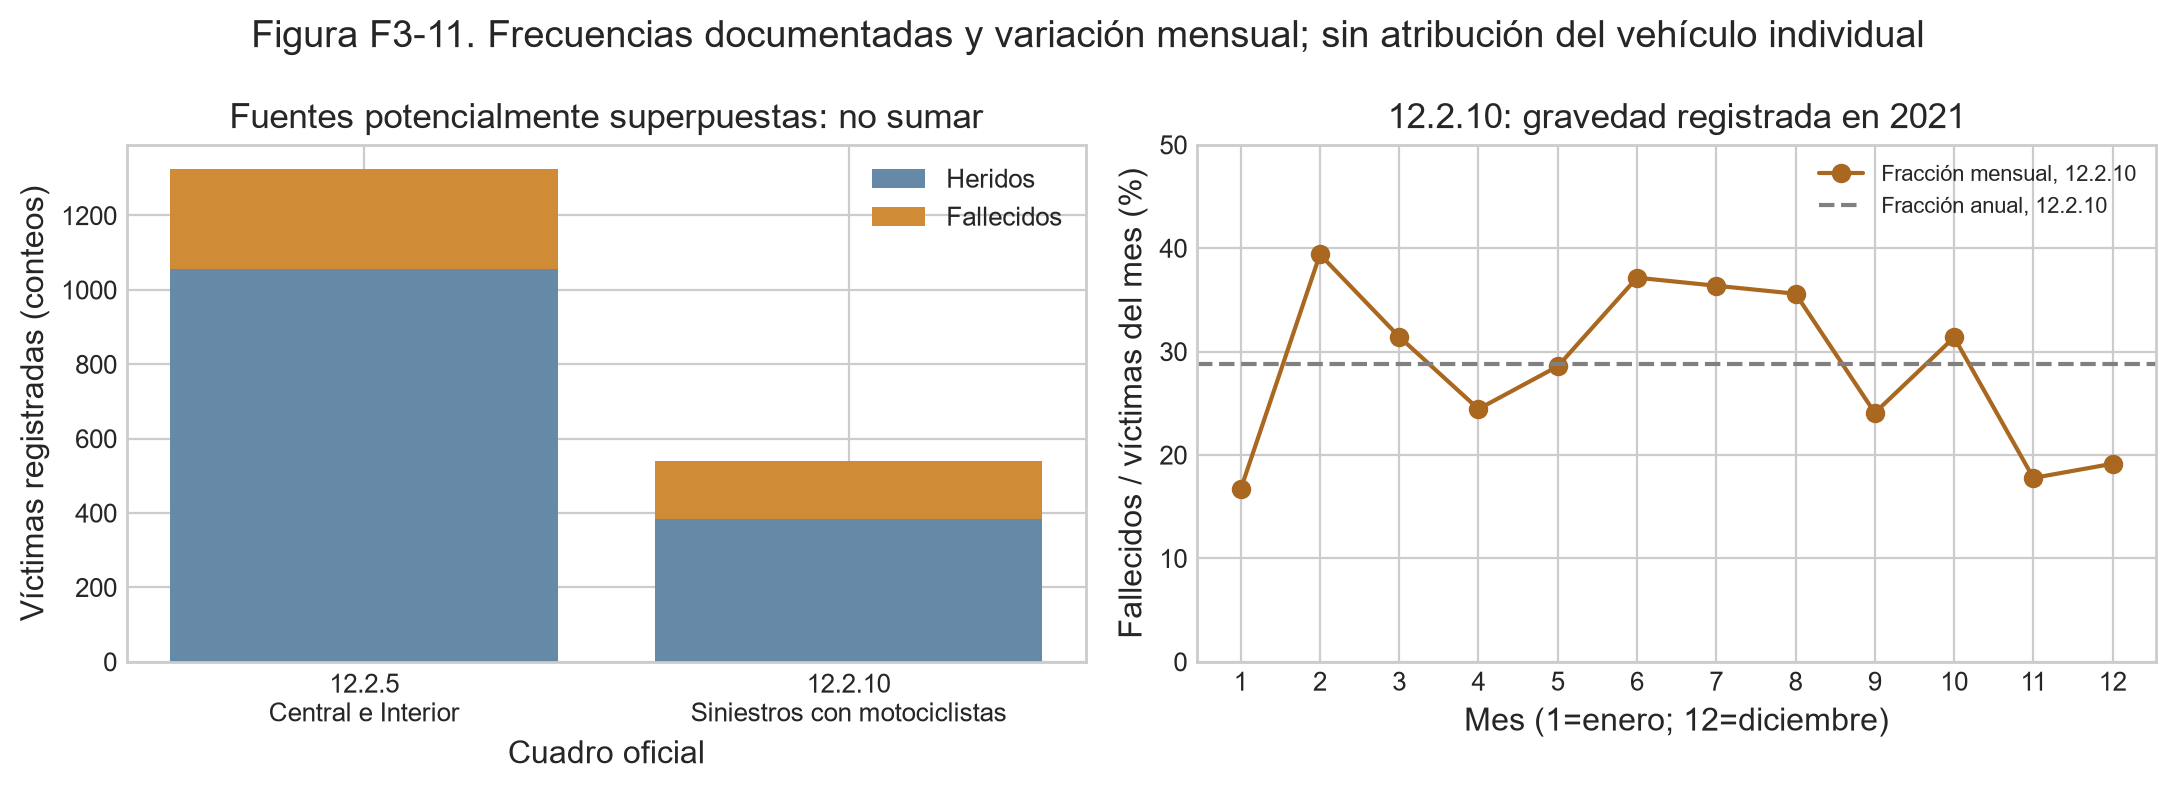

In [18]:
display(tabla_vehicular.round(4))
display(Markdown('**Lectura documental:** las primeras dos filas son coberturas potencialmente superpuestas; la tercera es una resta condicionada, no una categoría oficial de otros vehículos. Las fracciones usan el total de víctimas de cada fila.'))

display(Markdown('**Procedencia del CSV histórico:** las etiquetas Motociclista y Otro Vehiculo reproducen la construcción de Fase 1, pero sus nombres no quedan acreditados por las tablas oficiales. Verificar sus conteos no valida esas etiquetas.'))
mensual_vehicular = tablas_contexto['vehicular_mensual']

display(Markdown('**Cotejo mensual:** los totales de los doce meses coinciden con los anuales y todos los residuos son no negativos. Son condiciones aritméticas necesarias, insuficientes para demostrar universos y definiciones equivalentes.'))
fig_vehicular, axes_vehicular = plt.subplots(1, 2, figsize=(11, 4))
fuentes = tabla_vehicular.iloc[[1, 0]]
etiquetas = ['12.2.5\nCentral e Interior', '12.2.10\nSiniestros con motociclistas']
axes_vehicular[0].bar(etiquetas, fuentes.heridos, label='Heridos', color='#6689a7')
axes_vehicular[0].bar(etiquetas, fuentes.fallecidos, bottom=fuentes.heridos, label='Fallecidos', color='#cf8b36')
axes_vehicular[0].set(title='Fuentes potencialmente superpuestas: no sumar', ylabel='Víctimas registradas (conteos)', xlabel='Cuadro oficial')
axes_vehicular[0].legend()
fraccion_mensual = 100*mensual_vehicular.fallecidos_12_2_10/(mensual_vehicular.heridos_12_2_10+mensual_vehicular.fallecidos_12_2_10)
axes_vehicular[1].plot(np.arange(1, 13), fraccion_mensual, marker='o', color='#a96720', label='Fracción mensual, 12.2.10')
axes_vehicular[1].axhline(100*tabla_vehicular.iloc[0].fraccion_fallecidos, ls='--', color='grey', label='Fracción anual, 12.2.10')
axes_vehicular[1].set(title='12.2.10: gravedad registrada en 2021', xlabel='Mes (1=enero; 12=diciembre)', ylabel='Fallecidos / víctimas del mes (%)', xticks=range(1, 13), ylim=(0, 50))
axes_vehicular[1].legend(fontsize=8)
fig_vehicular.suptitle('Figura F3-11. Frecuencias documentadas y variación mensual; sin atribución del vehículo individual')
fig_vehicular.tight_layout()
plt.show()

### 7.4. H4 — Edad: dos preguntas distintas
**Pregunta ordinal:** ¿los fallecidos tienden a estar en rangos etarios superiores a los heridos? Mann-Whitney compara el orden de las distribuciones, no exclusivamente sus medianas. La alternativa `greater` mantiene la dirección histórica. Los rangos tienen amplitudes diferentes: no son edades exactas en años.

La versión anterior asignaba -1 a `Ignorado`, situándolo por debajo de los niños. La corrección usa **5.140 edades conocidas: 919 fallecidos y 4.221 heridos**. Los 353 desconocidos permanecen en el dataset nacional y en el clasificador nominal. Se muestra el antecedente solo para documentar la corrección.

U resume comparaciones de rangos entre los grupos, contando medio empate. El p-valor asintótico corrige empates y continuidad. El Z/r de Rosenthal conserva la definición histórica sin continuidad; se identifica como tamaño del efecto, no como un segundo p-valor. La correlación biserial de rangos mide la dirección y magnitud del ordenamiento.

**Bootstrap:** se remuestrean 2.000 veces las frecuencias de edad dentro de cada desenlace, semilla 42. Los percentiles 2,5 y 97,5 forman intervalos para el efecto biserial y la diferencia de medianas ordinales. Se asume muestreo independiente condicionado a los conteos; no captura siniestros compartidos o sesgos de cobertura. El IC de medianas [1;1] se refiere a una escala discreta de grupos, **no a un año exacto**.

**Pregunta de adultos mayores:** ¿es mayor la proporción fatal en 60 años o más que en menores de 60 conocidos? No es la misma pregunta que comparar toda la distribución ordinal. Fisher unilateral contrasta la tabla 2×2. RR divide proporciones; OR divide odds. Sus IC son logarítmicos (Katz/Woolf), no los bootstrap del contraste ordinal.

Se conserva Bonferroni de cuatro contrastes interpretables: H1, H2, H4 corregida y comparación adicional de 60 años. H3 no se acredita por su p histórico. Valores p pequeños no prueban causalidad ni ausencia de sesgo por edad faltante.

In [19]:
display(tablas_contexto['edad_auditoria'])
display(tablas_contexto['h4_ordinal'][['n_fallecidos','n_heridos','U','p','r_rosenthal','r_biserial','p_bonferroni_4']])
h4 = tablas_contexto['h4_ordinal'].loc['Corregido edad conocida']
adultos = tablas_contexto['h4_mayores60'].iloc[0]
print(f"H4: IC bootstrap biserial [{h4.ic95_r_biserial[0]:.4f}; {h4.ic95_r_biserial[1]:.4f}]; "
      f"diferencia de medianas {h4.diferencia_mediana:g}, IC {h4.ic95_diferencia_mediana}.")
display(tablas_contexto['h4_mayores60'][['fallecidos_mayores','heridos_mayores','fallecidos_menores','heridos_menores','RR','OR','p','p_bonferroni_4']])
print(f"RR={adultos.RR:.4f}, IC 95% [{adultos.ic95_RR[0]:.4f}; {adultos.ic95_RR[1]:.4f}]. "
      f"OR={adultos.OR:.4f}, IC 95% [{adultos.ic95_OR[0]:.4f}; {adultos.ic95_OR[1]:.4f}].")
display(Markdown('**Interpretación:** la corrección mantiene el rechazo estadístico de H4 bajo sus supuestos. La comparación específica de 60 años también muestra una proporción fatal mayor, con RR≈2,05. Son asociaciones condicionadas a las víctimas registradas y edades conocidas, sin demostrar causalidad ni riesgo individual futuro.'))

,victimas,heridos,fallecidos
grupo,,,
"Menor de 60, edad conocida",4832,4019,813
60 años o más,308,202,106
Edad desconocida,353,292,61


,n_fallecidos,n_heridos,U,p,r_rosenthal,r_biserial,p_bonferroni_4
Histórico con -1,980,4513,2576490.0,2.195670e-17,0.113364,0.165110,8.782681e-17
Corregido edad conocida,919,4221,2299236.0,1.656775e-20,0.128439,0.185448,6.627100e-20


H4: IC bootstrap biserial [0.1455; 0.2266]; diferencia de medianas 1, IC [1.0, 1.0].


,fallecidos_mayores,heridos_mayores,fallecidos_menores,heridos_menores,RR,OR,p,p_bonferroni_4
0,106,202,813,4019,2.045463,2.594072,4.808989e-13,1.923596e-12


RR=2.0455, IC 95% [1.7319; 2.4158]. OR=2.5941, IC 95% [2.0266; 3.3204].


**Interpretación:** la corrección mantiene el rechazo estadístico de H4 bajo sus supuestos. La comparación específica de 60 años también muestra una proporción fatal mayor, con RR≈2,05. Son asociaciones condicionadas a las víctimas registradas y edades conocidas, sin demostrar causalidad ni riesgo individual futuro.

## 8. Modelo guardado e inferencia
Se serializa solo el ganador ya entrenado con train; no se reajusta con test. El pipeline incorpora codificador y clasificador, y sus metadatos incluyen categorías aprendidas en train y versiones.

`src/inferencia.py` es el entregable independiente para datos nuevos del dominio permitido: carga el joblib, valida sexo/edad y devuelve clase y **puntuación no calibrada**, sin entrenar. Ejemplo: `python src/inferencia.py --sexo Mujer --grupo-edad Ignorado`. Una categoría desconocida arbitraria es rechazada. Uso admisible: académico y retrospectivo, sin triaje, seguros o vigilancia por perfil.

In [20]:
# Único artefacto persistente de modelado: pipeline ganador y sus metadatos.
categorias = {c: sorted(X_train_d[c].unique().tolist()) for c in columnas_categoricas}
metadatos = {'modelo': nombre_mejor_modelo, 'variables': columnas_categoricas,
             'categorias': categorias, 'puntuacion': 'no calibrada', 'semilla': RANDOM_STATE,
             'python_entrenamiento': sys.version,
             'sklearn_entrenamiento': __import__('sklearn').__version__,
             'sha256_fuente': auditoria_fuente['sha256_fuente'],
             'validacion': 'CV estratificada interna; test histórico inspeccionado; 16 perfiles repetidos'}
mejor_modelo_demografico.metadatos_fase3_ = metadatos
ruta_modelo = Path(OUTPUT_DIR) / 'fase3' / 'mejor_modelo_fase3.joblib'
ruta_modelo.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(mejor_modelo_demografico, ruta_modelo)
import importlib.metadata as metadata
versiones = {p: metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'scipy', 'matplotlib', 'joblib', 'nbclient', 'nbformat', 'nbconvert', 'ipykernel']}
versiones['python'] = sys.version
modelo_cargado = joblib.load(ruta_modelo)
assert np.array_equal(modelo_cargado.predict(X_test_d), mejor_modelo_demografico.predict(X_test_d))
print('Pipeline ganador y metadatos integrados: serialización y recarga verificadas.')

Pipeline ganador y metadatos integrados: serialización y recarga verificadas.


## 9. Conclusiones y respuesta a la pregunta original
La evidencia descriptiva, la inferencia y la predicción responden preguntas distintas. La siguiente conclusión se construye con resultados de esta ejecución y queda pendiente de revisión y defensa personal por el grupo.

In [21]:
sens = df_sensibilidad[['F1_macro', 'AUC_ROC']].mean()
cm = tablas_extra['matrices'].loc[nombre_mejor_modelo]
gini = tablas_extra['gini_variables'].loc['Árbol de Decisión'].sort_values(ascending=False)
conclusion = f"""**Modelo principal:** {nombre_mejor_modelo}, elegido por F1 macro CV={df_reporte_cv.loc[nombre_mejor_modelo, 'F1-Macro (Validación CV)']:.4f}. En la reserva histórica: accuracy={sel['Accuracy']:.4f}, precisión fallecidos={sel['Precision (Fallecido)']:.4f}, recall={sel['Recall (Fallecido)']:.4f}, F1 fallecidos={sel['F1-Score (Fallecido)']:.4f}, F1 macro={sel['F1-Macro']:.4f}, AUC={sel['ROC-AUC']:.4f}. Dummy tiene F1 macro={base['F1-Macro']:.4f} y recall cero; gana en accuracy y Brier. Mejorar F1 no demuestra calibración ni superioridad externa.

**Errores y generalización:** TN={int(cm.TN)}, FP={int(cm.FP)}, FN={int(cm.FN)}, TP={int(cm.TP)}. Omite todas las fallecidas mujeres y las fatalidades de 0–29 años de esta reserva, con solapamiento explicado en la sección 5. La diferencia F1 macro train−test={df_brechas.loc[nombre_mejor_modelo, 'Brecha Absoluta']:.4f} no descarta sobreajuste a perfiles repetidos. Con perfiles completos fuera: F1 macro medio={sens.F1_macro:.4f}, AUC={sens.AUC_ROC:.4f}; sensibilidad condicionada, no validación anidada o futura. {gini.index[0]} concentra la mayor importancia Gini ({gini.iloc[0]:.4f}), sin significado causal.

**Respuesta H1–H4:** H1 aporta tasas territoriales separadas; su GLM no mejora consistentemente la base. H2 es una asociación por sexo y predictor demográfico. H3 no acredita vehículo individual: no hay modelo vehicular válido. H4 corregida y la comparación de 60 años mantienen asociaciones etarias bajo supuestos, excluyendo desconocidos solo del contraste.

**Alcance:** la pregunta original se responde parcialmente. No hay vínculos individuales que permitan estimar efectos simultáneos de sexo, edad, vehículo y territorio. No se predice ocurrencia de accidentes ni se afirma causalidad. Harían falta microdatos vinculados de víctima/siniestro, vehículo real, fechas, protección, velocidad, lesión y atención, más validación externa y de calibración. No se atribuyen mecanismos biológicos a los errores ni se recomienda uso individual. El grupo debe revisar y defender estas decisiones e interpretaciones."""
display(Markdown(conclusion))

**Modelo principal:** Árbol de Decisión, elegido por F1 macro CV=0.5416. En la reserva histórica: accuracy=0.6351, precisión fallecidos=0.2324, recall=0.4541, F1 fallecidos=0.3074, F1 macro=0.5299, AUC=0.5809. Dummy tiene F1 macro=0.4510 y recall cero; gana en accuracy y Brier. Mejorar F1 no demuestra calibración ni superioridad externa.

**Errores y generalización:** TN=609, FP=294, FN=107, TP=89. Omite todas las fallecidas mujeres y las fatalidades de 0–29 años de esta reserva, con solapamiento explicado en la sección 5. La diferencia F1 macro train−test=0.0191 no descarta sobreajuste a perfiles repetidos. Con perfiles completos fuera: F1 macro medio=0.4556, AUC=0.5248; sensibilidad condicionada, no validación anidada o futura. grupo_edad concentra la mayor importancia Gini (0.5267), sin significado causal.

**Respuesta H1–H4:** H1 aporta tasas territoriales separadas; su GLM no mejora consistentemente la base. H2 es una asociación por sexo y predictor demográfico. H3 no acredita vehículo individual: no hay modelo vehicular válido. H4 corregida y la comparación de 60 años mantienen asociaciones etarias bajo supuestos, excluyendo desconocidos solo del contraste.

**Alcance:** la pregunta original se responde parcialmente. No hay vínculos individuales que permitan estimar efectos simultáneos de sexo, edad, vehículo y territorio. No se predice ocurrencia de accidentes ni se afirma causalidad. Harían falta microdatos vinculados de víctima/siniestro, vehículo real, fechas, protección, velocidad, lesión y atención, más validación externa y de calibración. No se atribuyen mecanismos biológicos a los errores ni se recomienda uso individual. El grupo debe revisar y defender estas decisiones e interpretaciones.

## 10. Anexo reproducible y comprobación de la consigna
Los detalles siguientes se conservan para revisión: no son nuevos experimentos ni variantes elegidas mirando test. Las métricas completas train/CV son visibles, las grillas registran todos los candidatos y los controles detallados también están en `tests/`. No es necesario memorizar cada fila para la exposición.

| Requisito | Evidencia y límite |
|---|---|
| 7.1.1–3: tarea, preparación y partición | Secciones 1–2; pipeline, semilla, categorías y desbalance; frecuencias agregadas |
| 7.1.4–6: base, familias, CV y grillas | Secciones 2–3; tres familias y búsquedas exclusivamente en train |
| 7.1.7: test al final | Sección 4; separación actual correcta, uso histórico único no demostrable |
| 7.1.8–9: errores e interpretación | Secciones 5–6; matrices, peores perfiles, coeficientes e importancias |
| 7.2: métricas y brechas | Sección 4 y este anexo; ambas clases, AUC, F1 y comparación train/CV/test |
| 7.3: conclusión | Sección 9; límites, sesgos, base, condiciones de uso y pregunta original |
| 7.4: notebook/HTML, modelo/inferencia, PDF e integrador | Notebook ejecutado, exportación HTML y sección 8; los PDF se revisan manualmente después |
| 9.3, 9.5, 10 y 12 | Métodos, ejecución y pruebas; la aprobación docente y el dominio personal no son automatizables |

Para reproducir: instalar `requirements-lock.txt`, ejecutar `python src/preparar_datos.py`, abrir el notebook con ese entorno, reiniciar kernel y ejecutar todo. Guardar salidas y exportar HTML según README. Ejecutar `python -m unittest discover -s tests -v` por separado. Los documentos y ZIP se preparan manualmente; esta simplificación no modifica `docs/`, fuentes ni notebooks históricos.

In [22]:
display(Markdown('**Métricas completas de entrenamiento**'))
display(metricas_train.round(4))
display(Markdown('**Métricas completas de validación cruzada** — Brier positivo: menor es mejor.'))
display(pd.DataFrame(cv_metricas).round(4))
for nombre, tabla_grid in grillas_cv.items():
    display(Markdown('**Grilla de entrenamiento: ' + nombre + '**'))
    display(tabla_grid[['params','mean_train_f1_macro','mean_test_f1_macro','std_test_f1_macro','rank_test_f1_macro']].sort_values('rank_test_f1_macro'))
for clave in ['errores_perfil','errores_edad','gini_indicadores','calibracion','sensibilidad_todos']:
    display(Markdown('**Detalle: ' + clave + '**'))
    display(tablas_extra[clave].round(4))
for clave in ['vehicular_procedencia','vehicular_mensual','territorio_mensual','territorio_predicciones','h4_ordinal','h4_mayores60','hipotesis_integradas']:
    display(Markdown('**Detalle: ' + clave + '**'))
    display(tablas_contexto[clave])

**Métricas completas de entrenamiento**

,Accuracy,Precision (Fallecido),Recall (Fallecido),F1-Score (Fallecido),F1-Macro,ROC-AUC,Precision (Herido),F1-Score (Herido),Specificity,Balanced Accuracy,Brier,Average Precision
Línea Base (Dummy),0.8216,0.0000,0.0000,0.0000,0.4510,0.5000,0.8216,0.9020,1.0000,0.5000,0.1784,0.1784
Regresión Logística,0.6234,0.2418,0.5204,0.3302,0.5341,0.6216,0.8611,0.7380,0.6457,0.5831,0.2375,0.2513
Árbol de Decisión,0.6623,0.2514,0.4515,0.3230,0.5490,0.6181,0.8560,0.7750,0.7080,0.5798,0.2379,0.2471
Random Forest,0.5995,0.2348,0.5510,0.3293,0.5219,0.6204,0.8622,0.7145,0.6100,0.5805,0.2400,0.2505
Naive Bayes Categórico,0.6234,0.2418,0.5204,0.3302,0.5341,0.6222,0.8611,0.7380,0.6457,0.5831,0.2377,0.2511


**Métricas completas de validación cruzada** — Brier positivo: menor es mejor.

,Modelo,metrica,media_train,media_validacion,desvio_validacion
0,Línea Base (Dummy),f1_macro,0.4510,0.4510,0.0001
1,Línea Base (Dummy),accuracy,0.8216,0.8216,0.0004
2,Línea Base (Dummy),precision,0.0000,0.0000,0.0000
3,Línea Base (Dummy),recall,0.0000,0.0000,0.0000
4,Línea Base (Dummy),f1,0.0000,0.0000,0.0000
5,Línea Base (Dummy),auc,0.5000,0.5000,0.0000
6,Línea Base (Dummy),precision_herido,0.8216,0.8216,0.0004
7,Línea Base (Dummy),recall_herido,1.0000,1.0000,0.0000
8,Línea Base (Dummy),f1_herido,0.9020,0.9020,0.0002
9,Línea Base (Dummy),balanced_accuracy,0.5000,0.5000,0.0000


**Grilla de entrenamiento: Regresión Logística**

...

,n_fallecidos,n_heridos,U,p,Z,r_rosenthal,r_biserial,ic95_r_biserial,diferencia_mediana,ic95_diferencia_mediana,bootstrap,semilla,p_bonferroni_4
Histórico con -1,980,4513,2576490.0,2.195670e-17,8.401959,0.113364,0.165110,"[0.12299113219406978, 0.20588974255778097]",1.0,"[0.0, 1.0]",2000,42,8.782681e-17
Corregido edad conocida,919,4221,2299236.0,1.656775e-20,9.208305,0.128439,0.185448,"[0.1454667952532276, 0.2266236373446514]",1.0,"[1.0, 1.0]",2000,42,6.627100e-20


**Detalle: h4_mayores60**

,fallecidos_mayores,heridos_mayores,fallecidos_menores,heridos_menores,RR,OR,ic95_RR,ic95_OR,p,p_bonferroni_4
0,106,202,813,4019,2.045463,2.594072,"[1.7318616723664073, 2.4158493942177004]","[2.0266255327675, 3.320399982911879]",4.808989e-13,1.923596e-12


**Detalle: hipotesis_integradas**

,factor,fuente,evidencia,limite
hipotesis,,,,
H1,Zona,12.2.6,Tasas y contraste histórico territorial,Cobertura y agrupación; no vínculo individual
H2,Sexo,12.2.1,Asociación histórica y predictor demográfico,Señal limitada; no causa ni riesgo individual
H3,Motocicletas,12.2.5 / 12.2.10,Descripción y contraste histórico condicionado,Rol de víctima y subconjunto no acreditados
H4,Edad,12.2.1,Ordinal corregido y contraste de 60 años; pred...,Inferencia condicional a frecuencias; 353 desc...


### Evidencia estructurada para verificación
Se guardan las mismas tablas numéricas y metadatos que antes, con entradas explícitas. Este bloque sirve a las pruebas; los métodos y resultados ya están expuestos arriba y no dependen de leer un formato técnico oculto.

In [23]:
tablas_publicadas = {
    'metricas_test': df_resultados_test, 'validacion': df_reporte_cv,
    'brechas': df_brechas, 'coeficientes': df_coef,
    'metricas_train': metricas_train, 'metricas_cv': pd.DataFrame(cv_metricas),
    'vehicular': tabla_vehicular, 'sensibilidad_ganador': df_sensibilidad,
    **tablas_contexto, **tablas_extra,
    **{'grilla_' + nombre: tabla[['params','mean_train_f1_macro','mean_test_f1_macro','std_test_f1_macro','rank_test_f1_macro']]
       .assign(params=lambda d: d.params.astype(str)) for nombre, tabla in grillas_cv.items()}}
publicar_resultados(tablas_publicadas, seleccion=seleccion_cerrada, metadatos=metadatos,
    versiones=versiones, solapamiento=solapamiento_FN, equivalencia=equivalencia_frecuencias,
    conclusiones=conclusion, procedencia=auditoria_fuente, contexto=auditoria_contexto)

Evidencia estructurada para comprobar resultados; las tablas de estudio se muestran en las secciones anteriores.

## Referencias y uso de IA
- INE. Anuario 2021: tablas 12.2.1 y 12.2.2 a 12.2.12 disponibles en el repositorio. [Catálogo oficial](https://www.datos.gov.py/dataset/anuario-2021-estadisticas-policiales-y-de-accidentes-de-transito). Las instituciones generadoras y coberturas difieren.
- Scikit-learn. [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html), [validación cruzada y grupos](https://scikit-learn.org/stable/modules/cross_validation.html), [importancia por permutación](https://scikit-learn.org/stable/modules/permutation_importance.html), [calibración](https://scikit-learn.org/stable/modules/calibration.html). Consulta: 16/10/2026.
- Consigna local: Proyecto_DataScience_Tres_Fases.pdf, apartados 7, 9.3, 9.5, 10, 11 y 12.
- Fases 1 y 2: notebooks y salidas históricas del repositorio; no se reescribieron como parte de esta revisión.

**Uso de IA:** Codex asistió en la auditoría, implementación, depuración, generación de documentación y propuestas de interpretación. El grupo debe comprender, revisar y defender personalmente las decisiones, el código y las interpretaciones antes de entregar. No se atribuye autoría o validación científica automática a los integrantes. La asistencia empleada excedió una simple corrección de sintaxis; corresponde al grupo revisar su compatibilidad con el artículo 11 y consultar al docente cuando proceda.

- INE. [Anuario Estadístico 2021, PDF original](https://www.ine.gov.py/Publicaciones/Biblioteca/documento/240/Anuario%20Estadistico%202021.pdf), páginas 307 (12.2.5/12.2.6) y 311 (12.2.10). Se cotejaron encabezados, fuentes y frecuencias; no se encontró acreditación del vehículo individual.